In [10]:
# ============================================================================
# 三分级有序分类绘图 - 导入模块
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
from datetime import datetime
from matplotlib import patheffects

warnings.filterwarnings('ignore')


# ============================================================================
# 评估指标和可视化
# ============================================================================
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    roc_curve, auc, roc_auc_score,
    precision_score, recall_score, brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize

from scipy.stats import kruskal, spearmanr
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# ============================================================================
# 绘图配置
# ============================================================================
plt.rcParams['pdf.fonttype'] = 42          # TrueType字体，PDF可编辑
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False # 负号显示正常
sns.set_style("whitegrid")

In [4]:
# ============================================================================
# 有序分类评估指标计算
# ============================================================================

def quadratic_weighted_kappa(y_true, y_pred, n_classes=3):
    """二次加权Kappa（最适合有序分类任务）"""
    weights = np.zeros((n_classes, n_classes))
    for i in range(n_classes):
        for j in range(n_classes):
            weights[i, j] = (i - j) ** 2
    
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes)).astype(float)
    n = np.sum(cm)
    if n == 0:
        return 0.0
    
    # 观测一致性
    observed = 1 - np.sum(weights * cm) / n
    
    # 期望一致性
    row_sum, col_sum = np.sum(cm, axis=1), np.sum(cm, axis=0)
    expected_cm = np.outer(row_sum, col_sum) / n
    expected = 1 - np.sum(weights * expected_cm) / n
    
    return 1.0 if expected == 1 else (observed - expected) / (1 - expected)

def ranked_probability_score(y_true, y_proba):
    """排名概率得分（RPS）- 考虑有序性的评估指标"""
    n_samples, n_classes = len(y_true), y_proba.shape[1]
    rps = 0
    for i in range(n_samples):
        cum_pred = np.cumsum(y_proba[i])
        cum_true = np.zeros(n_classes)
        cum_true[int(y_true[i]):] = 1.0
        rps += np.sum((cum_pred - cum_true) ** 2)
    return rps / n_samples

def mean_absolute_error_ordinal(y_true, y_pred):
    """有序MAE - 考虑类别顺序的误差距离"""
    return np.mean(np.abs(y_true - y_pred))

def macro_auc_ovr(y_true, y_proba, n_classes=3):
    """宏平均AUC（One-vs-Rest）"""
    aucs = []
    for i in range(n_classes):
        y_bin = (y_true == i).astype(int)
        if len(np.unique(y_bin)) >= 2:
            try:
                aucs.append(roc_auc_score(y_bin, y_proba[:, i]))
            except:
                pass
    return np.mean(aucs) if aucs else np.nan

def micro_auc_ovr(y_true, y_proba, n_classes=3):
    """微平均AUC - 展平所有类别计算"""
    y_bin = label_binarize(y_true, classes=range(n_classes))
    try:
        return roc_auc_score(y_bin.ravel(), y_proba.ravel())
    except:
        return np.nan

def weighted_auc_ovr(y_true, y_proba, n_classes=3):
    """加权平均AUC - 按类别样本比例加权"""
    from collections import Counter
    class_counts = Counter(y_true)
    total = len(y_true)
    weighted_auc, total_weight = 0, 0
    
    for i in range(n_classes):
        y_bin = (y_true == i).astype(int)
        if len(np.unique(y_bin)) >= 2:
            try:
                auc_i = roc_auc_score(y_bin, y_proba[:, i])
                weight = class_counts.get(i, 0) / total
                weighted_auc += auc_i * weight
                total_weight += weight
            except:
                pass
    
    return weighted_auc / total_weight if total_weight > 0 else np.nan

def calculate_sensitivity_specificity_per_class(y_true, y_pred, n_classes=3):
    """每类灵敏度(Sensitivity)和特异度(Specificity)"""
    sensitivities, specificities = [], []
    
    for i in range(n_classes):
        y_bin = (y_true == i).astype(int)
        y_pred_bin = (y_pred == i).astype(int)
        
        tp = np.sum((y_bin == 1) & (y_pred_bin == 1))
        tn = np.sum((y_bin == 0) & (y_pred_bin == 0))
        fp = np.sum((y_bin == 0) & (y_pred_bin == 1))
        fn = np.sum((y_bin == 1) & (y_pred_bin == 0))
        
        sensitivities.append(tp / (tp + fn) if (tp + fn) > 0 else 0.0)
        specificities.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    
    return sensitivities, specificities

def calculate_ppv_npv_per_class(y_true, y_pred, n_classes=3):
    """每类阳性预测值(PPV)和阴性预测值(NPV)"""
    ppvs, npvs = [], []
    
    for i in range(n_classes):
        y_bin = (y_true == i).astype(int)
        y_pred_bin = (y_pred == i).astype(int)
        
        tp = np.sum((y_bin == 1) & (y_pred_bin == 1))
        tn = np.sum((y_bin == 0) & (y_pred_bin == 0))
        fp = np.sum((y_bin == 0) & (y_pred_bin == 1))
        fn = np.sum((y_bin == 1) & (y_pred_bin == 0))
        
        ppvs.append(tp / (tp + fp) if (tp + fp) > 0 else 0.0)
        npvs.append(tn / (tn + fn) if (tn + fn) > 0 else 0.0)
    
    return ppvs, npvs

def calculate_all_metrics(y_true, y_pred, y_proba, n_classes=3):
    """
    计算所有评估指标
    
    指标类别：
    - 基础: Accuracy, Precision, Recall, F1
    - 有序: QWK, RPS, MAE
    - AUC: Macro/Micro/Weighted
    - 每类详细指标: 每个类别的F1, Precision, Recall, Sensitivity, Specificity, PPV, NPV, AUC
    """
    metrics = {}
    
    # ========== 基础分类指标 ==========
    metrics['Accuracy'] = accuracy_score(y_true, y_pred)
    
    for avg_type in ['Weighted', 'Macro', 'Micro']:
        metrics[f'{avg_type}_F1'] = f1_score(y_true, y_pred, average=avg_type.lower(), zero_division=0)
        metrics[f'{avg_type}_Precision'] = precision_score(y_true, y_pred, average=avg_type.lower(), zero_division=0)
        metrics[f'{avg_type}_Recall'] = recall_score(y_true, y_pred, average=avg_type.lower(), zero_division=0)
    
    # ========== 有序分类指标 ==========
    metrics['QWK'] = quadratic_weighted_kappa(y_true, y_pred, n_classes)
    metrics['RPS'] = ranked_probability_score(y_true, y_proba)
    metrics['MAE'] = mean_absolute_error_ordinal(y_true, y_pred)
    
    # ========== AUC指标 ==========
    metrics['Macro_AUC'] = macro_auc_ovr(y_true, y_proba, n_classes)
    metrics['Micro_AUC'] = micro_auc_ovr(y_true, y_proba, n_classes)
    metrics['Weighted_AUC'] = weighted_auc_ovr(y_true, y_proba, n_classes)
    
    # ========== 每类指标 ==========
    f1_per_class = f1_score(y_true, y_pred, average=None, zero_division=0)
    precision_per_class = precision_score(y_true, y_pred, average=None, zero_division=0)
    recall_per_class = recall_score(y_true, y_pred, average=None, zero_division=0)
    sensitivities, specificities = calculate_sensitivity_specificity_per_class(y_true, y_pred, n_classes)
    ppvs, npvs = calculate_ppv_npv_per_class(y_true, y_pred, n_classes)
    
    class_names = ['G1', 'G2', 'G3']
    for i, class_name in enumerate(class_names):
        metrics[f'F1_{class_name}'] = f1_per_class[i] if i < len(f1_per_class) else 0.0
        metrics[f'Precision_{class_name}'] = precision_per_class[i] if i < len(precision_per_class) else 0.0
        metrics[f'Recall_{class_name}'] = recall_per_class[i] if i < len(recall_per_class) else 0.0
        metrics[f'Sensitivity_{class_name}'] = sensitivities[i]
        metrics[f'Specificity_{class_name}'] = specificities[i]
        metrics[f'PPV_{class_name}'] = ppvs[i]
        metrics[f'NPV_{class_name}'] = npvs[i]
        
        # 每类AUC
        y_bin = (y_true == i).astype(int)
        if len(np.unique(y_bin)) >= 2:
            try:
                metrics[f'AUC_{class_name}'] = roc_auc_score(y_bin, y_proba[:, i])
            except:
                metrics[f'AUC_{class_name}'] = np.nan
        else:
            metrics[f'AUC_{class_name}'] = np.nan
    
    return metrics

def calculate_metrics_with_ci(
    y_true,
    y_pred,
    y_proba,
    n_classes=3,
    n_bootstraps=1000,
    ci=95,
    random_state=42,
    stratified=True
):
    """
    使用 bootstrap 计算有序三分类模型所有指标的95%置信区间。

    Parameters
    ----------
    y_true : array-like, shape (n_samples,)
        真实标签，例如 0,1,2
    y_pred : array-like, shape (n_samples,)
        预测标签，例如 0,1,2
    y_proba : array-like, shape (n_samples, n_classes)
        每个类别的预测概率
    n_classes : int
        类别数，默认3
    n_bootstraps : int
        bootstrap重复次数，默认1000
    ci : float
        置信区间，默认95
    random_state : int
        随机种子
    stratified : bool
        是否分层bootstrap。三分类不平衡时建议True。

    Returns
    -------
    results : dict
        每个指标的 point estimate, lower CI, upper CI
    boot_metrics_df : pandas.DataFrame
        每次bootstrap得到的指标结果
    """

    import numpy as np
    import pandas as pd

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_proba = np.asarray(y_proba)

    rng = np.random.default_rng(random_state)
    n_samples = len(y_true)

    # 原始点估计
    point_metrics = calculate_all_metrics(
        y_true=y_true,
        y_pred=y_pred,
        y_proba=y_proba,
        n_classes=n_classes
    )

    boot_metrics = []

    # 提前保存每一类的索引，用于分层bootstrap
    class_indices = {
        c: np.where(y_true == c)[0]
        for c in range(n_classes)
    }

    for b in range(n_bootstraps):

        if stratified:
            # 分层bootstrap：每个类别内部有放回抽样，保持类别比例基本不变
            indices = []
            for c in range(n_classes):
                idx_c = class_indices[c]
                if len(idx_c) == 0:
                    continue
                sampled_c = rng.choice(idx_c, size=len(idx_c), replace=True)
                indices.extend(sampled_c)
            indices = np.array(indices)
            rng.shuffle(indices)
        else:
            # 普通bootstrap
            indices = rng.choice(np.arange(n_samples), size=n_samples, replace=True)

            # 避免某次抽样后只剩一个类别，导致部分AUC无法计算
            if len(np.unique(y_true[indices])) < 2:
                continue

        y_true_b = y_true[indices]
        y_pred_b = y_pred[indices]
        y_proba_b = y_proba[indices]

        try:
            metrics_b = calculate_all_metrics(
                y_true=y_true_b,
                y_pred=y_pred_b,
                y_proba=y_proba_b,
                n_classes=n_classes
            )
            boot_metrics.append(metrics_b)
        except Exception:
            continue

    boot_metrics_df = pd.DataFrame(boot_metrics)

    alpha = (100 - ci) / 2
    lower_q = alpha
    upper_q = 100 - alpha

    results = {}

    for metric_name, point_value in point_metrics.items():
        if metric_name not in boot_metrics_df.columns:
            results[metric_name] = {
                "estimate": point_value,
                "ci_lower": np.nan,
                "ci_upper": np.nan
            }
            continue

        values = boot_metrics_df[metric_name].dropna().values

        if len(values) == 0:
            ci_lower, ci_upper = np.nan, np.nan
        else:
            ci_lower = np.percentile(values, lower_q)
            ci_upper = np.percentile(values, upper_q)

        results[metric_name] = {
            "estimate": point_value,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper
        }

    return results, boot_metrics_df

# ============================================================================
# 有序分类可视化评估
# ============================================================================
def plot_multiclass_roc(y_true, y_proba, title, save_path, n_classes=3):
    """Plot multi-class ROC curves"""
    y_true = np.array(y_true)
    y_proba = np.array(y_proba)
    
    unique_classes = np.unique(y_true)
    if not all(c in unique_classes for c in range(n_classes)):
        mapping = {c: i for i, c in enumerate(sorted(unique_classes))}
        y_true = np.array([mapping.get(y, y) for y in y_true])
    
    y_bin = label_binarize(y_true, classes=range(n_classes))
    if n_classes == 2:
        y_bin = np.hstack([1 - y_bin, y_bin])
    
    fig, ax = plt.subplots(figsize=(9, 8))
    class_names = ['G1', 'G2', 'G3/Cancer']
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
    
    for i in range(n_classes):
        if i >= y_proba.shape[1]:
            continue
        try:
            fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, color=colors[i], linewidth=3.5,
                # drawstyle='steps-post',
                label=f'{class_names[i]} (AUC={roc_auc:.3f})', alpha=0.9)
        except:
            pass
    
    ax.plot([0, 1], [0, 1], 'k--', linewidth=2, alpha=0.4, label='Chance')
    ax.set_xlabel('False Positive Rate', fontsize=14, fontweight='bold')
    ax.set_ylabel('True Positive Rate', fontsize=14, fontweight='bold')
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    ax.legend(loc='lower right', fontsize=11, framealpha=0.95)
    ax.grid(alpha=0.3, linestyle='--')
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.text(0.98, 0.02, f'N={len(y_true)}', transform=ax.transAxes,
           fontsize=11, ha='right', va='bottom',
           bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.replace('.png', '.pdf'), dpi=300, bbox_inches='tight')
    plt.close()


def plot_confusion_matrix(y_true, y_pred, title, save_path, n_classes=3):
    """Plot confusion matrix (no grid lines)"""
    class_names = ['G1', 'G2', 'G3/Cancer']
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
    cm_norm = cm.astype('float') / (cm.sum(axis=1, keepdims=True) + 1e-9)
    
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    ax.grid(False)
    
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            color = "white" if cm_norm[i, j] > 0.5 else "black"
            weight = 'bold' if i == j else 'normal'
            ax.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.1%})",
                   ha="center", va="center", color=color, fontsize=14, weight=weight)
    
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Predicted Grade', fontsize=14, fontweight='bold')
    ax.set_ylabel('True Grade', fontsize=14, fontweight='bold')
    ax.set_xticks(range(n_classes))
    ax.set_xticklabels(class_names)
    ax.set_yticks(range(n_classes))
    ax.set_yticklabels(class_names)
    ax.tick_params(axis='both', which='both', length=0)
    
    for spine in ax.spines.values():
        spine.set_linewidth(2)
    
    cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
    cbar.ax.set_ylabel('Proportion', fontsize=12, fontweight='bold', rotation=270, labelpad=20)
    
    acc = accuracy_score(y_true, y_pred)
    ax.text(0.02, 0.98, f'Accuracy: {acc:.1%}\nN={len(y_true)}',
           transform=ax.transAxes, fontsize=12, va='top',
           bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))
    
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.replace('.png', '.pdf'), dpi=300, bbox_inches='tight')
    plt.close()


def plot_calibration_curves(y_true, y_proba, title, save_path, n_classes=3, n_bins=5):
    """Plot calibration curves"""
    class_names = ['G1', 'G2', 'G3/Cancer']
    colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
    
    fig, axes = plt.subplots(1, n_classes, figsize=(16, 5))
    
    for i in range(n_classes):
        y_bin = (np.array(y_true) == i).astype(int)
        ax = axes[i]
        
        if len(np.unique(y_bin)) < 2:
            ax.text(0.5, 0.5, "N/A", ha='center', va='center',
                   fontsize=16, color='gray', transform=ax.transAxes)
            ax.set_title(class_names[i], fontsize=14, fontweight='bold')
            continue
        
        try:
            prob_true, prob_pred = calibration_curve(y_bin, y_proba[:, i],
                                                    n_bins=n_bins, strategy='uniform')
            brier = brier_score_loss(y_bin, y_proba[:, i])
            
            ax.plot(prob_pred, prob_true, "o-", color=colors[i], markersize=10,
                   linewidth=3.5, label="Model", alpha=0.9,
                   markeredgecolor='white', markeredgewidth=1.5)
            ax.plot([0, 1], [0, 1], 'k--', linewidth=2.5, label="Perfect Calibration", alpha=0.5)
            ax.fill_between(prob_pred, prob_pred, prob_true, alpha=0.2, color=colors[i])
            
            ax.set_title(f'{class_names[i]}\n(Brier={brier:.3f})',
                        fontsize=15, fontweight='bold', pad=10)
            ax.set_xlabel('Predicted Probability', fontsize=14, fontweight='bold')
            ax.set_ylabel('Observed Fraction of Positives', fontsize=14, fontweight='bold')
            ax.legend(fontsize=12, loc='upper left')
            ax.grid(ls="--", alpha=0.4)
            ax.set_xlim([-0.02, 1.02])
            ax.set_ylim([-0.02, 1.02])
            
            n_pos = y_bin.sum()
            ax.text(0.98, 0.02, f'Positives: {n_pos}/{len(y_bin)}',
                   transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
        except Exception as e:
            ax.text(0.5, 0.5, f"Error:\n{str(e)[:20]}", ha='center', va='center',
                   fontsize=14, color='red', transform=ax.transAxes)
    
    fig.suptitle(title, fontsize=19, fontweight='bold', y=1.02)
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.replace('.png', '.pdf'), dpi=300, bbox_inches='tight')
    plt.close()

In [ ]:
#============================================================================
# 指标计算, 绘图可视化
#============================================================================

# ============================================================================
# 数据准备, 读取结果表格，绘制图表数据
# ============================================================================

# train_prob = pd.read_excel("./results/best/results/results_proba.xlsx", sheet_name="Train_Proba")
# inter_prob = pd.read_excel("./results/best/results/results_proba.xlsx", sheet_name="Internal_Proba")
# exter_prob = pd.read_excel("./results/best/results/results_proba.xlsx", sheet_name="External_Proba")
train_prob = pd.read_excel("./results/best/results/train_proba.xlsx")
inter_prob = pd.read_excel("./results/best/results/inter_proba.xlsx")
exter_prob = pd.read_excel("./results/best/results/exter_proba.xlsx")

# print(train_prob.head())

# 对比不同的combo和不同model不同数据集的比较

def prepare_data(df):
    """Extract y_true, y_pred, y_proba from DataFrame"""
    y_true = df['y_true'].values
    y_pred = df['y_pred'].values
    y_proba = df[['prob_G0', 'prob_G1', 'prob_G2']].values
    return y_true, y_pred, y_proba


def get_groups(df):
    """Get all combo × model groups"""
    return df.groupby(['combo', 'model'])


# ============================================================================
# 主流程：遍历所有 combo × model × dataset
# ============================================================================
figure_path = "./results/best/figures"

datasets = {
    'Train':    train_prob,
    'Internal': inter_prob,
    'External': exter_prob,
}

all_metrics = []

for split_name, df in datasets.items():
    for (combo, model), group in get_groups(df):

        y_true, y_pred, y_proba = prepare_data(group)

        # ---------- 指标计算 ----------
        metrics = calculate_all_metrics(y_true, y_pred, y_proba, n_classes=3)
        metrics['combo']   = combo
        metrics['model']   = model
        metrics['dataset'] = split_name
        metrics['N']       = len(y_true)
        all_metrics.append(metrics)

        # ---------- 路径前缀 ----------
        base_dir = f"{figure_path}/{combo}_{model}_{split_name}"
        tag      = f"{combo}_{model}_{split_name}"

        # ---------- ROC曲线 ----------
        plot_multiclass_roc(
            y_true, y_proba,
            title     = f"ROC Curve — {combo} | {model} | {split_name}",
            save_path = f"{base_dir}/roc_{tag}.png",
        )

        # ---------- 混淆矩阵 ----------
        plot_confusion_matrix(
            y_true, y_pred,
            title     = f"Confusion Matrix — {combo} | {model} | {split_name}",
            save_path = f"{base_dir}/cm_{tag}.png",
        )

        # ---------- 校准曲线 ----------
        plot_calibration_curves(
            y_true, y_proba,
            title     = f"Calibration Curves — {combo} | {model} | {split_name}",
            save_path = f"{base_dir}/calib_{tag}.png",
        )

        print(f"✅ [{split_name}] {combo} × {model} — N={len(y_true)} — "
              f"Acc={metrics['Accuracy']:.3f}  QWK={metrics['QWK']:.3f}  "
              f"Macro_AUC={metrics['Macro_AUC']:.3f}")

# ============================================================================
# 汇总指标表格保存
# ============================================================================

metrics_df = pd.DataFrame(all_metrics)

meta_cols   = ['dataset', 'combo', 'model', 'N']
metric_cols = [c for c in metrics_df.columns if c not in meta_cols]
metrics_df  = metrics_df[meta_cols + metric_cols]
metrics_df  = metrics_df.sort_values(['combo', 'model', 'dataset']).reset_index(drop=True)

# out_path = "./results/best/results/all_metrics_summary.xlsx"
# os.makedirs(os.path.dirname(out_path), exist_ok=True)
# metrics_df.to_excel(out_path, index=False) 
# print(f"\n📊 Metrics summary saved to: {out_path}")
# print(metrics_df[['dataset', 'combo', 'model', 'Accuracy', 'QWK',
#                    'Macro_AUC', 'RPS', 'MAE']].to_string(index=False))

In [ ]:
#============================================================================
# 指标置信区间计算
#============================================================================

# ============================================================================
# 数据准备, 提取 y_true, y_pred, y_proba, 并计算指标
# ============================================================================
train_prob = pd.read_excel("./results/best/results/train_proba.xlsx")
inter_prob = pd.read_excel("./results/best/results/inter_proba.xlsx")
exter_prob = pd.read_excel("./results/best/results/exter_proba.xlsx")


def prepare_data(df):
    """Extract y_true, y_pred, y_proba from DataFrame"""
    y_true = df['y_true'].values.astype(int)
    y_pred = df['y_pred'].values.astype(int)
    y_proba = df[['prob_G0', 'prob_G1', 'prob_G2']].values.astype(float)
    return y_true, y_pred, y_proba


def get_groups(df):
    """Get all combo × model groups"""
    return df.groupby(['combo', 'model'])


def flatten_metrics_ci(results_ci, digits=3):
    """
    将 calculate_metrics_with_ci() 的结果压平成一行。

    输出字段示例：
    Accuracy
    Accuracy_CI_lower
    Accuracy_CI_upper
    Accuracy_95CI
    """
    flat = {}

    for metric_name, values in results_ci.items():
        estimate = values["estimate"]
        lower = values["ci_lower"]
        upper = values["ci_upper"]

        flat[metric_name] = estimate
        flat[f"{metric_name}_CI_lower"] = lower
        flat[f"{metric_name}_CI_upper"] = upper

        if pd.isna(estimate):
            flat[f"{metric_name}_95CI"] = "NA"
        elif pd.isna(lower) or pd.isna(upper):
            flat[f"{metric_name}_95CI"] = f"{estimate:.{digits}f}"
        else:
            flat[f"{metric_name}_95CI"] = (
                f"{estimate:.{digits}f} "
                f"({lower:.{digits}f}-{upper:.{digits}f})"
            )

    return flat


# ============================================================================
# 主流程：遍历所有 combo × model × dataset
# ============================================================================

figure_path = "./results/best/figures"
result_path = "./results/best/results"

os.makedirs(figure_path, exist_ok=True)
os.makedirs(result_path, exist_ok=True)

datasets = {
    'Train': train_prob,
    'Internal': inter_prob,
    'External': exter_prob,
}

all_metrics = []
all_metrics_with_ci = []

# 是否保存每个模型的bootstrap明细
save_bootstrap_detail = False

for split_name, df in datasets.items():
    for (combo, model), group in get_groups(df):
        
        print(split_name, combo, model)
        y_true, y_pred, y_proba = prepare_data(group)

        # ---------- 指标计算：点估计 ----------
        metrics = calculate_all_metrics(
            y_true=y_true,
            y_pred=y_pred,
            y_proba=y_proba,
            n_classes=3
        )

        metrics['combo'] = combo
        metrics['model'] = model
        metrics['dataset'] = split_name
        metrics['N'] = len(y_true)

        all_metrics.append(metrics)

        # ---------- 指标计算：95%CI ----------
        results_ci, boot_df = calculate_metrics_with_ci(
            y_true=y_true,
            y_pred=y_pred,
            y_proba=y_proba,
            n_classes=3,
            n_bootstraps=100,
            ci=95,
            random_state=42,
            stratified=True
        )

        metrics_ci_flat = flatten_metrics_ci(results_ci, digits=3)

        metrics_ci_flat['combo'] = combo
        metrics_ci_flat['model'] = model
        metrics_ci_flat['dataset'] = split_name
        metrics_ci_flat['N'] = len(y_true)

        all_metrics_with_ci.append(metrics_ci_flat)

        # ---------- 可选：保存bootstrap明细 ----------
        if save_bootstrap_detail:
            boot_dir = f"{result_path}/bootstrap_details"
            os.makedirs(boot_dir, exist_ok=True)

            boot_save_path = f"{boot_dir}/bootstrap_{combo}_{model}_{split_name}.xlsx"
            boot_df.to_excel(boot_save_path, index=False)


# ============================================================================
# 汇总指标表格保存：点估计
# ============================================================================

metrics_df = pd.DataFrame(all_metrics)

meta_cols = ['dataset', 'combo', 'model', 'N']
metric_cols = [c for c in metrics_df.columns if c not in meta_cols]
metrics_df = metrics_df[meta_cols + metric_cols]
metrics_df = metrics_df.sort_values(['combo', 'model', 'dataset']).reset_index(drop=True)

out_path = f"{result_path}/all_metrics_summary.xlsx"
metrics_df.to_excel(out_path, index=False)

print(f"\n📊 Metrics summary saved to: {out_path}")


# ============================================================================
# 汇总指标表格保存：带95%CI
# ============================================================================

metrics_ci_df = pd.DataFrame(all_metrics_with_ci)

meta_cols = ['dataset', 'combo', 'model', 'N']
metric_cols = [c for c in metrics_ci_df.columns if c not in meta_cols]
metrics_ci_df = metrics_ci_df[meta_cols + metric_cols]
metrics_ci_df = metrics_ci_df.sort_values(['combo', 'model', 'dataset']).reset_index(drop=True)

out_ci_path = f"{result_path}/all_metrics_summary_with_95CI.xlsx"
metrics_ci_df.to_excel(out_ci_path, index=False)

print(f"📊 Metrics summary with 95%CI saved to: {out_ci_path}")


# ============================================================================
# 额外保存一个更适合论文查看的简表
# ============================================================================

main_metrics = [
    'Accuracy',
    'Macro_F1',
    'Macro_Precision',
    'Macro_Recall',
    'QWK',
    'RPS',
    'MAE',
    'Macro_AUC',
    'Micro_AUC',
    'Weighted_AUC',
    'AUC_G1',
    'AUC_G2',
    'AUC_G3'
]

formatted_cols = [
    f"{m}_95CI" for m in main_metrics
    if f"{m}_95CI" in metrics_ci_df.columns
]

paper_table = metrics_ci_df[
    ['dataset', 'combo', 'model', 'N'] + formatted_cols
].copy()

# 把列名中的 _95CI 去掉，让表格更简洁
paper_table = paper_table.rename(
    columns={f"{m}_95CI": m for m in main_metrics if f"{m}_95CI" in paper_table.columns}
)

paper_table_path = f"{result_path}/all_metrics_paper_table_95CI.xlsx"
paper_table.to_excel(paper_table_path, index=False)

print(f"📄 Paper-style 95%CI table saved to: {paper_table_path}")


print(
    metrics_ci_df[
        [
            'dataset',
            'combo',
            'model',
            'Accuracy_95CI',
            'QWK_95CI',
            'Macro_AUC_95CI',
            'RPS_95CI',
            'MAE_95CI'
        ]
    ].to_string(index=False)
)

In [ ]:
# ============================================================================
# 结果可视化，雷达图
# ============================================================================

# =========================
# 0. 全局绘图风格
# =========================
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 11,
    "axes.linewidth": 1.0,
    "axes.edgecolor": "#333333",
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,   # 让 PDF 中字体可编辑
    "ps.fonttype": 42,
})


# =========================
# 1. 读取数据
# =========================
def load_metrics(file_path):
    """
    支持 csv / tsv / xlsx
    """
    file_path = Path(file_path)

    if file_path.suffix.lower() in [".xlsx", ".xls"]:
        df = pd.read_excel(file_path)
    elif file_path.suffix.lower() == ".csv":
        df = pd.read_csv(file_path)
    else:
        df = pd.read_csv(file_path, sep=r"\s+", engine="python")

    df.columns = df.columns.str.strip()

    for col in ["dataset", "combo", "model"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    return df


# =========================
# 2. 自动保存 png + pdf
# =========================
def save_figure_multi_format(fig, save_path, dpi=600, save_svg=False):
    """
    根据 save_path 自动保存 PNG 和 PDF。
    例如 save_path="./results/petal_internal_all.png"
    会生成：
    - petal_internal_all.png
    - petal_internal_all.pdf
    """
    if save_path is None:
        return

    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)

    png_path = save_path.with_suffix(".png")
    pdf_path = save_path.with_suffix(".pdf")

    fig.savefig(
        png_path,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )
    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"PNG 已保存到: {png_path}")
    print(f"PDF 矢量图已保存到: {pdf_path}")

    if save_svg:
        svg_path = save_path.with_suffix(".svg")
        fig.savefig(
            svg_path,
            bbox_inches="tight",
            facecolor="white"
        )
        print(f"SVG 矢量图已保存到: {svg_path}")


# =========================
# 3. 花瓣雷达图函数
# =========================
def plot_petal_radar(
    df,
    dataset="External",
    combo="All",
    models=None,
    metrics=None,
    reverse_metrics=("RPS", "MAE"),
    title=None,
    save_path=None,
    dpi=600,
    save_svg=False
):
    """
    绘制美化版花瓣雷达图。

    reverse_metrics:
        越小越好的指标，例如 RPS、MAE，会转换为 1 - value。
    """

    if metrics is None:
        metrics = [
            "Accuracy",
            "Macro_F1",
            "Macro_Precision",
            "Macro_Recall",
            "QWK",
            "RPS",
            "MAE",
            "Macro_AUC",
            "Micro_AUC",
            "Weighted_AUC",
            "AUC_G1",
            "AUC_G2",
            "AUC_G3",
        ]

    data = df[
        (df["dataset"] == dataset) &
        (df["combo"] == combo)
    ].copy()

    if models is not None:
        data = data[data["model"].isin(models)].copy()

    if data.empty:
        raise ValueError("筛选后没有数据，请检查 dataset、combo 或 models 是否正确。")

    if models is None:
        models = data["model"].tolist()

    # 只保留数据中存在的指标
    metrics = [m for m in metrics if m in data.columns]

    if len(metrics) < 3:
        raise ValueError("雷达图至少需要 3 个指标。")

    n_metrics = len(metrics)

    # 极坐标角度
    angles = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False)
    angles_closed = np.concatenate([angles, [angles[0]]])

    # 更适合论文的颜色
    color_map = {
        "DT": "#4E79A7",
        "GBDT": "#F28E2B",
        "KNN": "#59A14F",
        "LR": "#E15759",
        "RF": "#B07AA1",
        "SVM": "#76B7B2",
        "XGBoost": "#EDC948",
        "LightGBM": "#9C755F",
    }

    colors = [
        color_map.get(model, plt.cm.tab10(i % 10))
        for i, model in enumerate(models)
    ]

    # =========================
    # 建图
    # =========================
    fig = plt.figure(figsize=(10.5, 9.5))
    ax = fig.add_subplot(111, polar=True)

    # 雷达图起始角度和方向
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    # 背景
    fig.patch.set_facecolor("white")
    ax.set_facecolor("#FAFAFA")

    # 外框
    ax.spines["polar"].set_color("#333333")
    ax.spines["polar"].set_linewidth(1.2)

    # 坐标标签
    display_labels = []
    for m in metrics:
        if m in reverse_metrics:
            display_labels.append(f"{m}\n(reversed)")
        else:
            display_labels.append(m)

    ax.set_xticks(angles)
    ax.set_xticklabels(display_labels, fontsize=10, color="#222222")

    # 调整标签距离
    ax.tick_params(axis="x", pad=12)

    # 半径范围
    ax.set_ylim(0, 1.0)

    # 径向网格
    radial_ticks = [0.2, 0.4, 0.6, 0.8, 1.0]
    ax.set_yticks(radial_ticks)
    ax.set_yticklabels(
        [f"{t:.1f}" for t in radial_ticks],
        fontsize=9,
        color="#666666"
    )

    # 将径向标签放到较空的位置
    ax.set_rlabel_position(90)

    # 网格样式
    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.8,
        color="#BDBDBD",
        alpha=0.65
    )
    ax.xaxis.grid(
        True,
        linestyle="-",
        linewidth=0.6,
        color="#D9D9D9",
        alpha=0.55
    )

    # =========================
    # 绘制每个模型
    # =========================
    for color, model in zip(colors, models):
        row = data[data["model"] == model]

        if row.empty:
            print(f"警告：模型 {model} 在当前筛选条件下没有数据，已跳过。")
            continue

        row = row.iloc[0]

        values = []
        for m in metrics:
            v = float(row[m])

            if m in reverse_metrics:
                v = 1 - v

            # 防止超出 0-1 范围
            v = np.clip(v, 0, 1)
            values.append(v)

        values_closed = np.concatenate([values, [values[0]]])

        ax.plot(
            angles_closed,
            values_closed,
            color=color,
            linewidth=2.2,
            label=model,
            marker="o",
            markersize=4.5,
            markerfacecolor="white",
            markeredgewidth=1.4,
            alpha=0.95
        )

        ax.fill(
            angles_closed,
            values_closed,
            color=color,
            alpha=0.10
        )

    # =========================
    # 标题和图例
    # =========================
    if title is None:
        title = f"Model Performance Radar Plot\nDataset: {dataset} | Feature set: {combo}"

    ax.set_title(
        title,
        fontsize=16,
        fontweight="bold",
        color="#111111",
        pad=30
    )

    legend = ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=min(len(models), 6),
        frameon=True,
        fontsize=10,
        handlelength=2.0,
        columnspacing=1.3
    )

    legend.get_frame().set_facecolor("white")
    legend.get_frame().set_edgecolor("#CCCCCC")
    legend.get_frame().set_linewidth(0.8)

    # 图下注释
    fig.text(
        0.5,
        0.015,
        "Note: RPS and MAE were reversed as 1 - value, so higher values consistently indicate better performance.",
        ha="center",
        va="center",
        fontsize=9,
        color="#555555"
    )

    plt.tight_layout(rect=[0.02, 0.06, 0.98, 0.96])

    # 保存 PNG + PDF
    save_figure_multi_format(
        fig,
        save_path=save_path,
        dpi=dpi,
        save_svg=save_svg
    )

    plt.show()

    return fig, ax


# =========================
# 4. 使用示例
# =========================
if __name__ == "__main__":
    df = load_metrics("./results/best/results/all_metrics_summary0.xlsx")

    model_order = ["DT", "GBDT", "KNN", "LR", "RF", "SVM"]

    plot_petal_radar(
        df,
        dataset="Internal",
        combo="All",
        models=model_order,
        title="Internal Cohort | All Features",
        save_path="./results/petal_internal_all.png",
        save_svg=True
    )

    plot_petal_radar(
        df,
        dataset="External",
        combo="All",
        models=model_order,
        title="External Cohort | All Features",
        save_path="./results/petal_external_all.png",
        save_svg=True
    )

C:\Users\21332\AppData\Local\Temp\ipykernel_34088\1667733557.py:162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


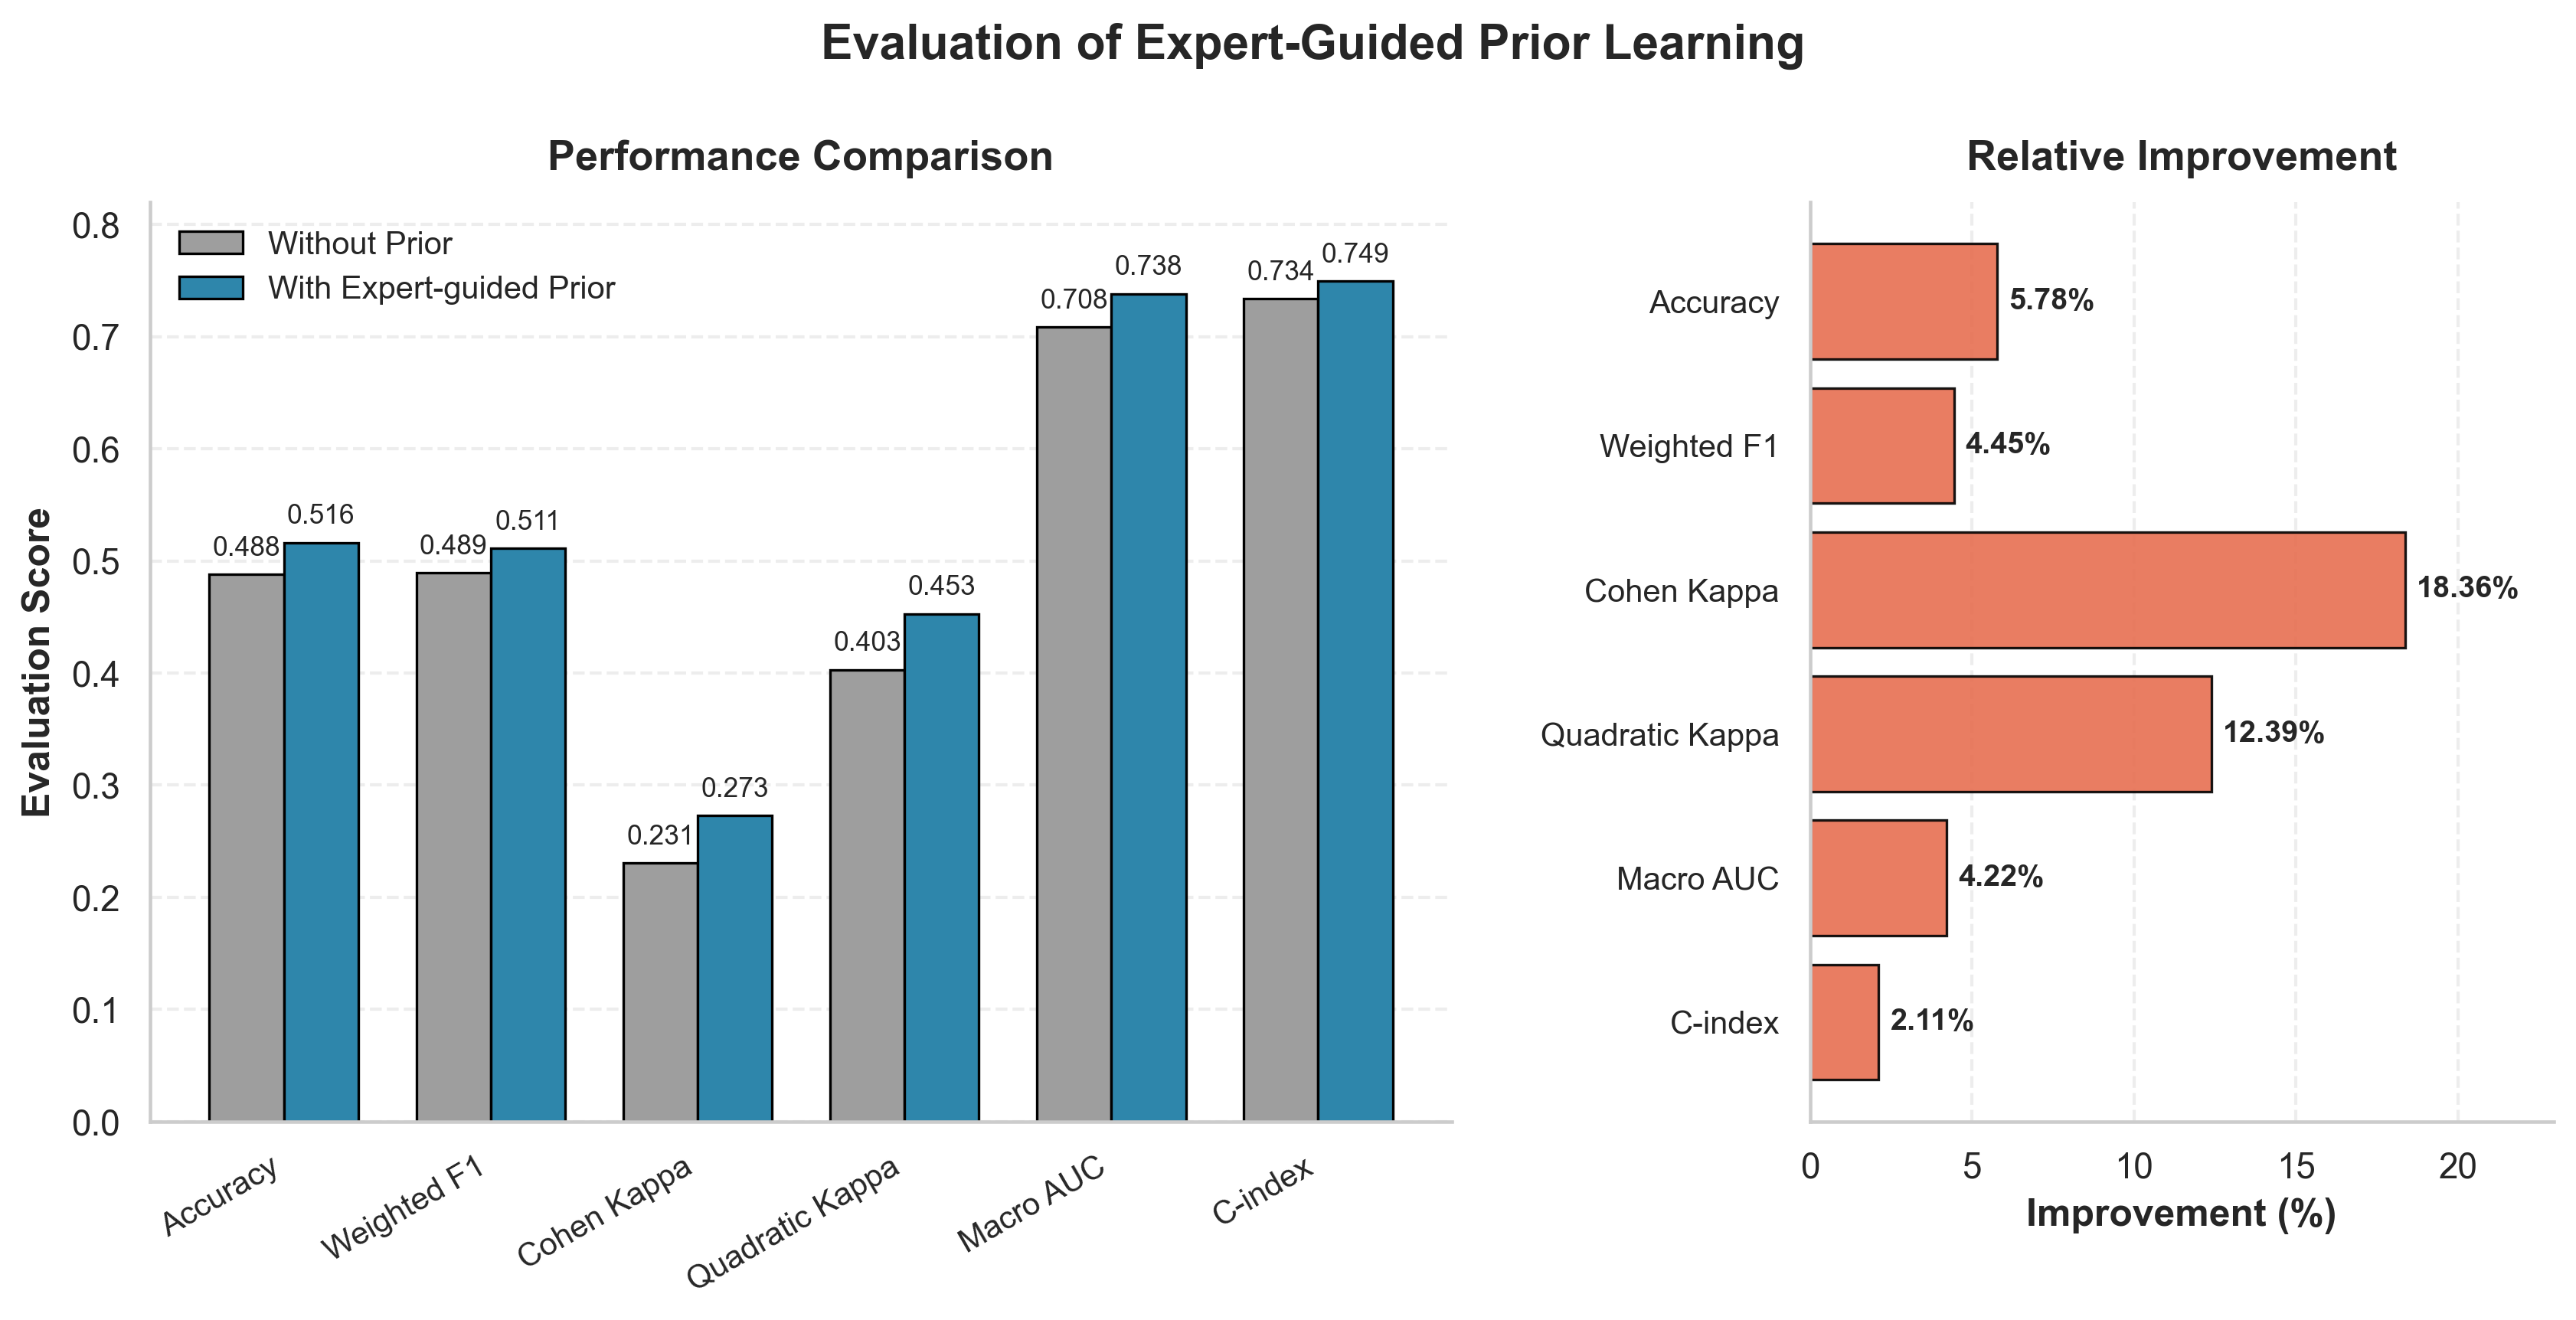

In [ ]:
# ============================================================================
# 结果可视化，加点先验和不加点先验的对比
# ============================================================================ 

# =========================
# Data
# =========================
data = {
    "Metric": [
        "Accuracy",
        "Weighted F1",
        "Cohen Kappa",
        "Quadratic Kappa",
        "Macro AUC",
        "C-index"
    ],
    "Without Prior": [0.4881, 0.4895, 0.2307, 0.4029, 0.7083, 0.7337],
    "With Prior":    [0.5163, 0.5113, 0.2731, 0.4528, 0.7382, 0.7492],
    "Improvement (%)": [5.78, 4.45, 18.36, 12.39, 4.22, 2.11]
}

df = pd.DataFrame(data)

# =========================
# Style
# =========================
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# Colors
color_without = "#9E9E9E"
color_with = "#2E86AB"
color_improve = "#E76F51"

# =========================
# Figure layout
# =========================
fig = plt.figure(figsize=(13.5, 5.2), dpi=300)
gs = fig.add_gridspec(1, 2, width_ratios=[2.1, 1.2], wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

# =========================
# Left panel: grouped bar plot
# =========================
metrics = df["Metric"].values
x = np.arange(len(metrics))
bar_width = 0.36

bars1 = ax1.bar(
    x - bar_width / 2,
    df["Without Prior"],
    width=bar_width,
    color=color_without,
    edgecolor="black",
    linewidth=0.8,
    label="Without Prior"
)

bars2 = ax1.bar(
    x + bar_width / 2,
    df["With Prior"],
    width=bar_width,
    color=color_with,
    edgecolor="black",
    linewidth=0.8,
    label="With Expert-guided Prior"
)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=8.5
        )

ax1.set_xticks(x)
ax1.set_xticklabels(metrics, rotation=30, ha="right", fontsize=10)
ax1.set_ylabel("Evaluation Score", fontsize=12, fontweight="bold")
ax1.set_ylim(0, 0.82)
ax1.set_title(
    "Performance Comparison",
    fontsize=13,
    fontweight="bold",
    pad=10
)
ax1.legend(frameon=False, fontsize=10, loc="upper left")
ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.grid(axis="x", visible=False)

# =========================
# Right panel: improvement plot
# =========================
y = np.arange(len(metrics))

bars3 = ax2.barh(
    y,
    df["Improvement (%)"],
    color=color_improve,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.9
)

ax2.set_yticks(y)
ax2.set_yticklabels(metrics, fontsize=10)
ax2.invert_yaxis()
ax2.set_xlabel("Improvement (%)", fontsize=12, fontweight="bold")
ax2.set_title(
    "Relative Improvement",
    fontsize=13,
    fontweight="bold",
    pad=10
)
ax2.set_xlim(0, max(df["Improvement (%)"]) * 1.25)
ax2.grid(axis="x", linestyle="--", alpha=0.35)
ax2.grid(axis="y", visible=False)

# Add percentage labels
for bar, val in zip(bars3, df["Improvement (%)"]):
    ax2.text(
        val + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.2f}%",
        va="center",
        ha="left",
        fontsize=9.5,
        fontweight="bold"
    )

# =========================
# Clean spines
# =========================
for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.1)
    ax.spines["bottom"].set_linewidth(1.1)

# =========================
# Main title
# =========================
fig.suptitle(
    "Evaluation of Expert-Guided Prior Learning",
    fontsize=15,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()

# =========================
# Save
# =========================
plt.savefig("expert_guided_prior_learning_evaluation.png", dpi=600, bbox_inches="tight")
plt.savefig("expert_guided_prior_learning_evaluation.pdf", bbox_inches="tight")

plt.show()

In [ ]:
# ============================================================================
# 异质性评分和ki-67的统计结果可视化
# ============================================================================

from scipy import stats
from scipy.stats import spearmanr, pearsonr, kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

import warnings
warnings.filterwarnings("ignore")


# ============================================================
# 全局绘图风格
# ============================================================

def set_publication_style():
    sns.set_theme(style="white", context="paper")
    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "axes.linewidth": 1.0,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "figure.dpi": 300,
        "savefig.dpi": 300,
    })


# ============================================================
# 工具函数
# ============================================================

def format_pvalue(p):
    if p < 0.001:
        return "p < 0.001"
    elif p < 0.01:
        return f"p = {p:.3f}"
    else:
        return f"p = {p:.3f}"


def clean_data(
    df,
    score_col="THI",
    ki67_col="ki67",
    pred_col="y_pred",
    grade_col="grade_label",
    ki67_eps=None
):
    """
    清洗数据：
    1. 保留 Ki67 = 0 的病例。
    2. 使用 y_pred 映射生成 grade_label。
       0 -> G1
       1 -> G2
       2 -> G3/Cancer
    3. 为 log 坐标生成 ki67_plot，避免 log(0)。
    """
    df = df.copy()

    required = [score_col, ki67_col, pred_col]
    for col in required:
        if col not in df.columns:
            raise ValueError(f"缺少必要列: {col}")

    df[score_col] = pd.to_numeric(df[score_col], errors="coerce")
    df[ki67_col] = pd.to_numeric(df[ki67_col], errors="coerce")
    df[pred_col] = pd.to_numeric(df[pred_col], errors="coerce")

    # 只删除真正缺失值，不删除 Ki67 = 0
    df = df.dropna(subset=[score_col, ki67_col, pred_col]).copy()

    # y_pred 映射为分级标签
    grade_map = {
        0: "G1",
        1: "G2",
        2: "G3/Cancer"
    }

    df[grade_col] = df[pred_col].astype(int).map(grade_map)

    # 如果存在非 0/1/2 标签，删除无法映射的行
    df = df.dropna(subset=[grade_col]).copy()

    grade_order = ["G1", "G2", "G3/Cancer"]
    df[grade_col] = pd.Categorical(
        df[grade_col],
        categories=grade_order,
        ordered=True
    )

    # 处理 Ki67 = 0：保留原始 Ki67，额外生成 log 绘图用列
    positive_ki67 = df.loc[df[ki67_col] > 0, ki67_col]

    if ki67_eps is None:
        if len(positive_ki67) > 0:
            ki67_eps = positive_ki67.min() / 2
        else:
            ki67_eps = 0.01

    df[f"{ki67_col}_plot"] = df[ki67_col].clip(lower=ki67_eps)

    print(f"[Ki67 log handling] Ki67 = 0 retained; plotting epsilon = {ki67_eps:.6g}")
    print(f"[Grade mapping] {pred_col}: 0 -> G1, 1 -> G2, 2 -> G3/Cancer")

    return df


def add_pvalue_bar(ax, x1, x2, y, h, p_text, fontsize=9):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.0, c="black")
    ax.text((x1 + x2) / 2, y + h, p_text, ha="center", va="bottom", fontsize=fontsize)


def summary_by_group(df, value_col, group_col):
    rows = []
    for g, sub in df.groupby(group_col):
        values = sub[value_col].dropna().values
        if len(values) == 0:
            continue
        rows.append({
            "group": g,
            "n": len(values),
            "mean": np.mean(values),
            "sd": np.std(values, ddof=1),
            "median": np.median(values),
            "q25": np.percentile(values, 25),
            "q75": np.percentile(values, 75),
        })
    return pd.DataFrame(rows)


# ============================================================
# 子图A：异质性评分 across WHO grades
# ============================================================

def plot_score_across_grades(
    df,
    score_col="THI",
    grade_col="WHO_grade",
    output_path=None,
    title=None
):
    set_publication_style()

    grade_order = ["G1", "G2", "G3/Cancer"]
    palette = {
        "G1": "#5B8FF9",
        "G2": "#61DDAA",
        "G3/Cancer": "#F46664"
    }

    df = df.dropna(subset=[score_col, grade_col]).copy()

    fig, ax = plt.subplots(figsize=(4.6, 4.2))

    # violin
    sns.violinplot(
        data=df,
        x=grade_col,
        y=score_col,
        order=grade_order,
        palette=palette,
        inner=None,
        linewidth=1.0,
        cut=0,
        alpha=0.65,
        ax=ax
    )

    # boxplot
    sns.boxplot(
        data=df,
        x=grade_col,
        y=score_col,
        order=grade_order,
        width=0.25,
        showcaps=True,
        boxprops={"facecolor": "white", "edgecolor": "black", "linewidth": 1.0},
        whiskerprops={"color": "black", "linewidth": 1.0},
        medianprops={"color": "black", "linewidth": 1.2},
        showfliers=False,
        ax=ax
    )

    # scatter jitter
    sns.stripplot(
        data=df,
        x=grade_col,
        y=score_col,
        order=grade_order,
        palette=palette,
        size=3.2,
        jitter=0.22,
        alpha=0.65,
        edgecolor="white",
        linewidth=0.25,
        ax=ax
    )

    # Kruskal-Wallis
    groups = [df.loc[df[grade_col] == g, score_col].dropna().values for g in grade_order]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) >= 2:
        kw_stat, kw_p = kruskal(*groups)
    else:
        kw_p = np.nan

    # pairwise Mann-Whitney
    pairs = [(0, 1), (1, 2), (0, 2)]
    pvals = []
    for i, j in pairs:
        g1 = grade_order[i]
        g2 = grade_order[j]
        v1 = df.loc[df[grade_col] == g1, score_col].dropna().values
        v2 = df.loc[df[grade_col] == g2, score_col].dropna().values
        if len(v1) > 0 and len(v2) > 0:
            _, p = mannwhitneyu(v1, v2, alternative="two-sided")
        else:
            p = np.nan
        pvals.append(p)

    # FDR校正
    valid = ~np.isnan(pvals)
    pvals_adj = np.array(pvals, dtype=float)
    if np.sum(valid) > 0:
        pvals_adj[valid] = multipletests(np.array(pvals)[valid], method="fdr_bh")[1]

    # 添加p值线
    y_min, y_max = df[score_col].min(), df[score_col].max()
    y_range = y_max - y_min
    base_y = y_max + 0.08 * y_range
    h = 0.04 * y_range

    add_pvalue_bar(ax, 0, 1, base_y, h, format_pvalue(pvals_adj[0]))
    add_pvalue_bar(ax, 1, 2, base_y + 0.13 * y_range, h, format_pvalue(pvals_adj[1]))
    add_pvalue_bar(ax, 0, 2, base_y + 0.26 * y_range, h, format_pvalue(pvals_adj[2]))

    # x标签加n
    xticklabels = []
    for g in grade_order:
        n = np.sum(df[grade_col] == g)
        xticklabels.append(f"{g}\n(n = {n})")
    ax.set_xticklabels(xticklabels)

    ax.set_xlabel("")
    ax.set_ylabel(score_col)
    ax.set_title(title if title else f"{score_col} across WHO grades", fontweight="bold")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.45 * y_range)

    # 输出摘要表到控制台
    print("\n[Summary across WHO grades]")
    print(summary_by_group(df, score_col, grade_col))
    print(f"Kruskal-Wallis {format_pvalue(kw_p)}")

    plt.tight_layout()

    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        fig.savefig(output_path, bbox_inches="tight")
        fig.savefig(output_path.replace(".png", ".pdf"), bbox_inches="tight")

    return fig, ax

# ============================================================
# 子图B：异质性评分 vs Ki-67 散点相关图
# ============================================================
def plot_score_ki67_correlation(
    df,
    score_col="THI",
    ki67_col="ki67",
    grade_col="grade_label",
    output_path=None,
    title=None,
    log_y=True
):
    set_publication_style()

    grade_order = ["G1", "G2", "G3/Cancer"]
    palette = {
        "G1": "#5B8FF9",
        "G2": "#61DDAA",
        "G3/Cancer": "#F46664"
    }

    ki67_plot_col = f"{ki67_col}_plot"

    if log_y and ki67_plot_col not in df.columns:
        raise ValueError(f"缺少 {ki67_plot_col}，请先运行 clean_data()")

    df = df.dropna(subset=[score_col, ki67_col, grade_col]).copy()

    # x = score, y = Ki67
    x = df[score_col].values
    y_raw = df[ki67_col].values
    y_plot_data = df[ki67_plot_col].values if log_y else df[ki67_col].values

    # Spearman 用原始值
    spearman_r, spearman_p = spearmanr(x, y_raw)

    # Pearson：log_y 时用 log10(Ki67_plot)
    if log_y:
        pearson_y = np.log10(y_plot_data)
    else:
        pearson_y = y_raw

    pearson_r, pearson_p = pearsonr(x, pearson_y)

    fig, ax = plt.subplots(figsize=(5.0, 4.2))

    # scatter
    for g in grade_order:
        sub = df[df[grade_col] == g]
        ax.scatter(
            sub[score_col],
            sub[ki67_plot_col] if log_y else sub[ki67_col],
            s=28,
            color=palette[g],
            alpha=0.68,
            edgecolor="white",
            linewidth=0.35,
            label=g
        )

    # regression line
    if log_y:
        y_model = np.log10(y_plot_data)
        y_plot = np.linspace(np.log10(y_plot_data.min()), np.log10(y_plot_data.max()), 200)
        y_plot_original = 10 ** y_plot
    else:
        y_model = y_raw
        y_plot = np.linspace(y_raw.min(), y_raw.max(), 200)
        y_plot_original = y_plot

    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y_model)
    y_pred = intercept + slope * x

    # 为了画回归线，需要在x范围上生成预测
    x_plot = np.linspace(x.min(), x.max(), 200)
    y_pred_line = intercept + slope * x_plot

    # 95% CI
    n = len(df)
    y_fit = intercept + slope * x
    residual = y_model - y_fit

    if n > 2:
        s_err = np.sqrt(np.sum(residual ** 2) / (n - 2))
        x_mean = np.mean(x)
        ssx = np.sum((x - x_mean) ** 2)

        t_val = stats.t.ppf(0.975, n - 2)
        ci = t_val * s_err * np.sqrt(
            1 / n + (x_plot - x_mean) ** 2 / (ssx + 1e-8)
        )
    else:
        ci = np.zeros_like(y_pred_line)

    ax.plot(x_plot, y_pred_line if not log_y else 10 ** y_pred_line, color="black", linewidth=2.0)
    ax.fill_between(
        x_plot,
        (y_pred_line - ci) if not log_y else 10 ** (y_pred_line - ci),
        (y_pred_line + ci) if not log_y else 10 ** (y_pred_line + ci),
        color="gray",
        alpha=0.25,
        linewidth=0
    )

    ax.set_xlabel(score_col)
    if log_y:
        ax.set_ylabel("Ki-67 index (%)")
        ax.set_yscale("log")
    else:
        ax.set_ylabel("Ki-67 index (%)")

    ax.set_title(
        title if title else f"Correlation between {score_col} and Ki-67 index",
        fontweight="bold"
    )

    # n_zero = np.sum(df[ki67_col] == 0)
    text = (
        f"Spearman ρ = {spearman_r:.2f}\n"
        f"{format_pvalue(spearman_p)}\n"
        # f"Ki-67 = 0 retained, n = {n_zero}"
    )

    ax.text(
        0.04, 0.96,
        text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        )
    )

    ax.legend(title="Predicted grade", frameon=False, loc="lower right")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(True, axis="y", linestyle="--", alpha=0.25)

    plt.tight_layout()

    print("\n[Correlation]")
    print(f"Spearman rho = {spearman_r:.4f}, {format_pvalue(spearman_p)}")
    print(f"Pearson r = {pearson_r:.4f}, {format_pvalue(pearson_p)}")
    # print(f"Ki67 = 0 retained: n = {n_zero}")

    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        fig.savefig(output_path, bbox_inches="tight")
        fig.savefig(output_path.replace(".png", ".pdf"), bbox_inches="tight")

    return fig, ax

# ============================================================
# 子图C：按评分水平分层后的 Ki-67 分布
# ============================================================

def assign_score_level(df, score_col="THI", cutoffs=None):
    """
    将异质性评分分成 Low / Intermediate / High 三组。
    默认用三分位数。
    也可以手动输入 cutoffs，例如 cutoffs=[40, 60]
    """
    df = df.copy()

    if cutoffs is None:
        q1, q2 = np.percentile(df[score_col].dropna(), [33.33, 66.67])
    else:
        q1, q2 = cutoffs

    def label_func(x):
        if x < q1:
            return f"Low {score_col}"
        elif x < q2:
            return f"Intermediate {score_col}"
        else:
            return f"High {score_col}"

    df[f"{score_col}_level"] = df[score_col].apply(label_func)

    return df, (q1, q2)

def plot_ki67_distribution_by_score_level(
    df,
    score_col="THI",
    ki67_col="ki67",
    grade_col="grade_label",
    cutoffs=None,
    output_path=None,
    min_kde_n=3
):
    """
    按异质性评分 Low / Intermediate / High 分层后，
    绘制不同预测分级中的 Ki-67 分布。

    修改：
    1. 每个子图加 title。
    2. 使用均值线，并在线旁标注均值数值。
    """

    set_publication_style()

    grade_order = ["G1", "G2", "G3/Cancer"]
    palette = {
        "G1": "#5B8FF9",
        "G2": "#61DDAA",
        "G3/Cancer": "#F46664"
    }

    ki67_plot_col = f"{ki67_col}_plot"

    if ki67_plot_col not in df.columns:
        raise ValueError(f"缺少 {ki67_plot_col}，请先运行 clean_data() 生成 log 绘图用 Ki-67 列")

    df = df.dropna(
        subset=[score_col, ki67_col, grade_col, ki67_plot_col]
    ).copy()

    df, used_cutoffs = assign_score_level(
        df,
        score_col=score_col,
        cutoffs=cutoffs
    )

    print(f"Used cutoffs: {used_cutoffs}")

    level_col = f"{score_col}_level"
    level_order = [
        f"Low {score_col}",
        f"Intermediate {score_col}",
        f"High {score_col}",
    ]

    eps = df[ki67_plot_col].min()

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(11.8, 3.8),
        sharey=True
    )

    all_handles = []
    all_labels = []

    for ax, level in zip(axes, level_order):
        sub_level = df[df[level_col] == level].copy()

        # 用于 title 显示各 grade 样本数
        grade_n_text = []

        # 用于避免均值文字重叠
        mean_label_y_positions = {
            "G1": 0.92,
            "G2": 0.82,
            "G3/Cancer": 0.72
        }

        for g in grade_order:
            sub = sub_level[sub_level[grade_col] == g].copy()

            values_plot = sub[ki67_plot_col].dropna().values
            values_raw = sub[ki67_col].dropna().values

            n_g = len(values_raw)
            grade_n_text.append(f"{g}: {n_g}")

            if len(values_plot) == 0:
                continue

            color = palette[g]

            # 样本数足够时画 KDE
            if len(values_plot) >= min_kde_n and len(np.unique(values_plot)) > 1:
                sns.kdeplot(
                    values_plot,
                    ax=ax,
                    color=color,
                    fill=True,
                    alpha=0.28,
                    linewidth=1.5,
                    label=g,
                    log_scale=True,
                    common_norm=False,
                    warn_singular=False
                )
            else:
                # 样本太少时，用散点标记
                ax.scatter(
                    values_plot,
                    np.zeros_like(values_plot) + 0.005,
                    color=color,
                    s=18,
                    alpha=0.75,
                    edgecolor="white",
                    linewidth=0.3,
                    label=g
                )

            # ====================================================
            # 均值线 + 均值数值
            # ====================================================
            mean_original = np.mean(values_raw)
            mean_plot = max(mean_original, eps)

            ax.axvline(
                mean_plot,
                color=color,
                linestyle="--",
                linewidth=1.25,
                alpha=0.95
            )

            # 在均值线附近标注均值
            # x 使用 mean_plot，y 使用轴坐标比例，避免受 density 高低影响
            ax.text(
                mean_plot,
                mean_label_y_positions[g],
                f"{mean_original:.1f}",
                color=color,
                fontsize=8,
                fontweight="bold",
                rotation=90,
                ha="right",
                va="center",
                transform=ax.get_xaxis_transform(),
                bbox=dict(
                    boxstyle="round,pad=0.15",
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.65
                )
            )

        # ====================================================
        # 子图 title
        # ====================================================
        n_level = len(sub_level)
        n_zero = np.sum(sub_level[ki67_col] == 0)

        ax.set_title(
            f"{level}\n"
            f"n = {n_level}; " + ", ".join(grade_n_text),
            fontweight="bold",
            fontsize=9
        )

        ax.set_xlabel("Ki-67 index (%)")
        ax.set_xscale("log")

        # x轴范围
        x_min = eps * 0.8
        x_max = df[ki67_plot_col].max() * 1.3
        ax.set_xlim(x_min, x_max)

        # 自定义 x 轴刻度
        candidate_ticks = [eps, 0.1, 1, 10, 100]
        ticks = [t for t in candidate_ticks if x_min <= t <= x_max]

        ticks_unique = []
        for t in ticks:
            if not ticks_unique or abs(np.log10(t) - np.log10(ticks_unique[-1])) > 0.15:
                ticks_unique.append(t)

        tick_labels = []
        for t in ticks_unique:
            if np.isclose(t, eps):
                tick_labels.append("0")
            else:
                tick_labels.append(f"{t:g}")

        ax.set_xticks(ticks_unique)
        ax.set_xticklabels(tick_labels)

        ax.grid(True, axis="y", linestyle="--", alpha=0.25)
        ax.grid(True, axis="x", linestyle="--", alpha=0.12)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # 收集 legend
        handles, labels = ax.get_legend_handles_labels()
        for h, lab in zip(handles, labels):
            if lab not in all_labels:
                all_handles.append(h)
                all_labels.append(lab)

        if ax.get_legend() is not None:
            ax.get_legend().remove()

    axes[0].set_ylabel("Density")
    axes[1].set_ylabel("")
    axes[2].set_ylabel("")

    # 统一图例
    if len(all_handles) > 0:
        fig.legend(
            all_handles,
            all_labels,
            title="Predicted grade",
            frameon=False,
            loc="center right",
            bbox_to_anchor=(1.02, 0.55)
        )

    plt.suptitle(
        f"Distribution of Ki-67 index across {score_col} levels",
        y=1.08,
        fontsize=12,
        fontweight="bold"
    )

    plt.tight_layout(rect=[0, 0, 0.92, 1])

    print(f"\n[{score_col} cutoffs]")
    print(f"Low < {used_cutoffs[0]:.4f}")
    print(f"Intermediate: {used_cutoffs[0]:.4f} - {used_cutoffs[1]:.4f}")
    print(f"High ≥ {used_cutoffs[1]:.4f}")
    print(f"Ki67 = 0 retained: n = {np.sum(df[ki67_col] == 0)}")
    print(f"Ki67 zero plotted at pseudo-value eps = {eps:.6g}")

    print("\n[Mean Ki67 by score level and predicted grade]")
    print(
        df.groupby([level_col, grade_col])[ki67_col]
        .agg(["count", "mean", "median"])
    )

    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        fig.savefig(output_path, bbox_inches="tight")
        fig.savefig(output_path.replace(".png", ".pdf"), bbox_inches="tight")

    return fig, axes, used_cutoffs


# ============================================================
# 主函数示例
# ============================================================

if __name__ == "__main__":

    input_path = "./results/score.xlsx"
    output_dir = "./results/figures_THI_Ki67"
    os.makedirs(output_dir, exist_ok=True)

    score_col = "THI"
    ki67_col = "ki67"
    pred_col = "y_true"
    grade_col = "grade_label"

    df = pd.read_excel(input_path)

    df = clean_data(
        df,
        score_col=score_col,
        ki67_col=ki67_col,
        pred_col=pred_col,
        grade_col=grade_col,
        ki67_eps=None
    )

    # 子图A
    plot_score_across_grades(
        df,
        score_col=score_col,
        grade_col=grade_col,
        output_path=os.path.join(output_dir, "A_score_across_predicted_grades.png"),
        title=f"{score_col} across predicted grades"
    )

    # 子图B
    plot_score_ki67_correlation(
        df,
        score_col=score_col,
        ki67_col=ki67_col,
        grade_col=grade_col,
        output_path=os.path.join(output_dir, "B_THI_vs_Ki67.png"),
        title="Correlation between THI and Ki-67 index",
        log_y=True
    )

    # 子图C
    plot_ki67_distribution_by_score_level(
        df,
        score_col=score_col,
        ki67_col=ki67_col,
        grade_col=grade_col,
        # cutoffs=None,
        cutoffs=[0.333, 0.667],
        output_path=os.path.join(output_dir, "C_Ki67_by_score_level.png")
    )

In [ ]:
#============================================================================
# 做shap分析，可视化RF模型的feature importance
#============================================================================

# 输出目录
shap_output_dir = "./results/shap_RF_ordinal"
os.makedirs(shap_output_dir, exist_ok=True)

# ============================================================================
# [Step 1] 加载和合并数据
# ============================================================================

# 读取临床特征
clinical = pd.read_excel('./clinical/clinical_data.xlsx')
clinical['name_hospital'] = clinical['name'] + '_' + clinical['hospital']
clinical.set_index('name_hospital', inplace=True)
X_clinical = clinical.iloc[:, 2:-3]

# 读取影像特征
X_rad = pd.read_excel("./score/feature_rad.xlsx", index_col=0)

# 读取异质性特征
X_ith = pd.read_excel("./results/score.xlsx", index_col=0).loc[:,['THI']]

# 排序
X_rad = X_rad.sort_index()
X_ith = X_ith.sort_index()
X_clinical = X_clinical.sort_index()

# 读取标签信息, inter中split列存了train和inter，作为建模分组，grade列存了gt-012
inter = pd.read_csv("./data/inter.csv")
inter['name_hospital'] = inter['name'] + '_' + inter['hospital']
inter.set_index('name_hospital', inplace=True)

# outer grade列存了gt-012
exter = pd.read_csv("./data/outer.csv")
exter['name_hospital'] = exter['name'] + '_' + exter['hospital']
exter.set_index('name_hospital', inplace=True)

# 合并特征和标签
X_all = pd.concat([X_rad, X_ith, X_clinical], axis=1)

# 分组
train_index = inter[inter['split'] == 'train'].index
inter_index = inter[inter['split'] == 'inter'].index

X_train = X_all.loc[train_index, :]
X_inter = X_all.loc[inter_index, :]
y_train = inter.loc[train_index, 'grade']
y_inter = inter.loc[inter_index, 'grade']

X_exter = X_all.loc[exter.index, :]
y_exter = exter.loc[:, 'grade']
print(f"\n✓ 特征和标签合并完成")

class OrdinalFeatureSelector:
    """
    有序多分类特征筛选器 - 精简版
    
    筛选流程：
    1. 缺失值 + 方差 → 移除无效特征
    2. Kruskal-Wallis检验 → 移除类间无差异特征
    3. 互信息 → 移除信息量低特征
    4. 斯皮尔曼相关 → 移除冗余特征
    5. 重要性评分 → 综合排序
    """
    
    def __init__(self, 
                 variance_threshold=0.01,
                 missing_threshold=0.1,
                 correlation_threshold=0.95,
                 pvalue_threshold=0.05,
                 mi_threshold=None,
                 n_top_features=None,
                 verbose=True,
                 random_state=42):
        
        self.variance_threshold = variance_threshold
        self.missing_threshold = missing_threshold
        self.correlation_threshold = correlation_threshold
        self.pvalue_threshold = pvalue_threshold
        self.mi_threshold = mi_threshold
        self.n_top_features = n_top_features
        self.verbose = verbose
        self.random_state = random_state
        
        self.removal_log = {}
        self.feature_scores = {}
    
    def fit_transform(self, X, y, feature_list=None):
        """
        执行特征筛选
        
        参数：
            X: DataFrame - 特征矩阵
            y: array-like - 目标变量(0,1,2)
            feature_list: list - 特征列表
        
        返回：
            X_selected: DataFrame - 筛选后特征
            kept_features: list - 保留特征名称
        """
        
        if feature_list is None:
            feature_list = X.columns.tolist()
        
        X_work = X[feature_list].copy()
        y_work = np.asarray(y, dtype=int)
        
        if self.verbose:
            print(f"\n{'='*70}\n🔍 有序三分类特征筛选\n{'='*70}")
            print(f"输入: {X_work.shape[0]} 样本 × {len(feature_list)} 特征")
            print(f"类别分布: {dict(enumerate(np.bincount(y_work)))}\n")
        
        kept_features = set(feature_list)
        
        # ===== 筛选1: 缺失值 & 方差 =====
        if self.verbose:
            print(f"[1/5] 缺失值与方差筛选")
        
        removed = []
        for col in list(kept_features):
            if col not in X_work.columns:
                continue
            
            # 缺失值检查
            missing_ratio = X_work[col].isna().sum() / len(X_work)
            if missing_ratio > self.missing_threshold:
                removed.append(col)
                self.removal_log[col] = f"缺失值{missing_ratio:.2%}"
                if self.verbose:
                    print(f"  ✗ {col:30s} - 缺失值 {missing_ratio:.2%}")
                continue
            
            # 方差检查
            var = X_work[col].var()
            if var < self.variance_threshold:
                removed.append(col)
                self.removal_log[col] = f"方差{var:.6f}"
                if self.verbose:
                    print(f"  ✗ {col:30s} - 方差 {var:.6f}")
        
        kept_features -= set(removed)
        if self.verbose:
            print(f"  ✓ 移除 {len(removed)} 个\n")
        
        # ===== 筛选2: Kruskal-Wallis检验 =====
        if self.verbose:
            print(f"[2/5] Kruskal-Wallis秩和检验 (有序类间差异)")
        
        removed = []
        kw_scores = {}
        
        # 按类别分组数据
        groups = [X_work.loc[y_work == c, :].values for c in np.unique(y_work)]
        
        for col in list(kept_features):
            if col not in X_work.columns:
                continue
            
            col_idx = list(X_work.columns).index(col)
            group_data = [g[:, col_idx] for g in groups]
            
            try:
                h_stat, pval = kruskal(*group_data)
                kw_scores[col] = h_stat
                
                if pval > self.pvalue_threshold:
                    removed.append(col)
                    self.removal_log[col] = f"KW检验p={pval:.4f}"
                    if self.verbose:
                        print(f"  ✗ {col:30s} - p值 {pval:.4f} (不显著)")
            except:
                removed.append(col)
                self.removal_log[col] = "KW检验失败"
        
        kept_features -= set(removed)
        if self.verbose:
            print(f"  ✓ 移除 {len(removed)} 个\n")
        
        # ===== 筛选3: 互信息 =====
        if self.verbose:
            print(f"[3/5] 互信息筛选 (特征-标签关联)")
        
        try:
            X_clean = X_work[list(kept_features)].fillna(0)
            X_scaled = StandardScaler().fit_transform(X_clean)
            
            mi_scores = mutual_info_classif(X_scaled, y_work, 
                                           random_state=self.random_state)
            mi_dict = dict(zip(X_clean.columns, mi_scores))
            
            # 自动阈值 = 中位数
            if self.mi_threshold is None:
                self.mi_threshold = np.median(list(mi_dict.values()))
            
            removed = [col for col, score in mi_dict.items() 
                      if score < self.mi_threshold]
            
            for col in removed:
                self.removal_log[col] = f"MI{mi_dict[col]:.4f}"
                if self.verbose:
                    print(f"  ✗ {col:30s} - MI {mi_dict[col]:.4f}")
            
            kept_features -= set(removed)
            if self.verbose:
                print(f"  ✓ 移除 {len(removed)} 个 (阈值={self.mi_threshold:.4f})\n")
        
        except Exception as e:
            if self.verbose:
                print(f"  ⚠ MI计算失败: {str(e)[:30]}\n")
        
        # ===== 筛选4: 斯皮尔曼相关 =====
        if self.verbose:
            print(f"[4/5] 斯皮尔曼相关性筛选 (移除冗余特征)")
        
        kept_list = list(kept_features)
        if len(kept_list) > 1:
            X_subset = X_work[kept_list].fillna(0)
            corr = X_subset.corr(method='spearman').abs()
            
            removed = set()
            
            # 找高相关对，保留与目标关联更强的
            for i in range(len(corr.columns)):
                for j in range(i + 1, len(corr.columns)):
                    if corr.iloc[i, j] >= self.correlation_threshold:
                        col1, col2 = corr.columns[i], corr.columns[j]
                        
                        # 与目标的相关性
                        corr1_y, _ = spearmanr(X_work[col1].fillna(0), y_work)
                        corr2_y, _ = spearmanr(X_work[col2].fillna(0), y_work)
                        
                        # 保留关联更强的
                        remove_col = col2 if abs(corr1_y) >= abs(corr2_y) else col1
                        removed.add(remove_col)
                        
                        self.removal_log[remove_col] = f"与{col1 if remove_col==col2 else col2}相关ρ={corr.iloc[i, j]:.3f}"
                        
                        if self.verbose:
                            print(f"  ✗ {remove_col:30s} - ρ {corr.iloc[i, j]:.3f}")
            
            kept_features -= removed
            if self.verbose:
                print(f"  ✓ 移除 {len(removed)} 个\n")
        
        # ===== 筛选5: 特征排序 & Top-K =====
        if self.verbose:
            print(f"[5/5] 特征重要性评分")
        
        kept_list = list(kept_features)
        X_final = X_work[kept_list].fillna(0)
        
        # 计算综合重要性: 0.6 × KW + 0.4 × MI
        importance = {}
        kw_max = max(kw_scores.values()) if kw_scores else 1
        
        for col in kept_list:
            kw_score = (kw_scores.get(col, 0) / kw_max) * 0.6
            
            try:
                X_scaled = StandardScaler().fit_transform(X_final[[col]])
                mi_score = mutual_info_classif(X_scaled, y_work, 
                                              random_state=self.random_state)[0]
                mi_all = mutual_info_classif(StandardScaler().fit_transform(X_final),
                                           y_work, random_state=self.random_state)
                mi_norm = (mi_score / max(mi_all)) * 0.4 if max(mi_all) > 0 else 0
            except:
                mi_norm = 0
            
            importance[col] = kw_score + mi_norm
        
        # 排序
        sorted_feats = sorted(importance.items(), key=lambda x: x[1], reverse=True)
        
        if self.verbose:
            print(f"  特征排序 (Top-10):")
            for i, (col, score) in enumerate(sorted_feats[:10], 1):
                print(f"    {i:2d}. {col:30s} │ 分数 {score:.4f}")
        
        # Top-K选择
        if self.n_top_features and self.n_top_features < len(kept_list):
            kept_list = [col for col, _ in sorted_feats[:self.n_top_features]]
            if self.verbose:
                print(f"  ✓ 选择 Top-{self.n_top_features} 特征\n")
        
        # ===== 最终结果 =====
        X_selected = X_work[kept_list].copy()
        
        if self.verbose:
            print(f"{'='*70}")
            print(f"原始: {len(feature_list)} → 保留: {len(kept_list)} "
                  f"({len(kept_list)/len(feature_list)*100:.1f}%)")
            print(f"{'='*70}\n")
        
        return X_selected, kept_list

# 做特征筛选
selector = OrdinalFeatureSelector(
        variance_threshold=0.01,
        pvalue_threshold=0.05,
        correlation_threshold=0.9,
        mi_threshold=None,
        n_top_features=None,
        verbose=True,
        random_state=42)

X_train_selected, kept_features = selector.fit_transform(
        X_train,
        y_train,
        feature_list=X_train.columns.tolist()
    )

print(kept_features)


model = RandomForestClassifier(
        n_estimators=200,              # 300棵足够，过多无益
        max_depth=7,                   # 小样本不宜太深
        # min_samples_split=20,          # 约占样本6-7%
        min_samples_leaf=5,           # 约占样本3%
        max_features='sqrt',           # 5-30特征时sqrt合适
        # max_samples=0.8,               # 每棵树80%样本，增加多样性
        bootstrap=True,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    )

model.fit(X_train_selected, y_train)
class_names = ['G1', 'G2', 'G3/Cancer']
n_classes = 3

# 确保 X_train_selected 是 DataFrame，保留特征名
if not isinstance(X_train_selected, pd.DataFrame):
    X_train_selected = pd.DataFrame(
        X_train_selected,
        columns=kept_features,
        index=X_train.index
    )

# 如果有测试集，也做同样特征筛选
X_test_selected = X_inter[kept_features].copy()

# ============================================================
# 1. 构建 TreeExplainer
# ============================================================

explainer = shap.TreeExplainer(model)

# 对训练集或测试集计算 SHAP
# 推荐优先解释测试集，如果测试集太小也可以解释训练集
X_shap = X_test_selected.copy()

shap_values = explainer.shap_values(X_shap)

print("Type of shap_values:", type(shap_values))

if isinstance(shap_values, list):
    for i, sv in enumerate(shap_values):
        print(f"Class {i} SHAP shape:", sv.shape)
else:
    print("SHAP values shape:", shap_values.shape)

# ============================================================
# 2. 统一 SHAP values 格式为 list[class] -> array(n_samples, n_features)
# ============================================================

if isinstance(shap_values, list):
    shap_values_list = shap_values
else:
    # 常见形状: (n_samples, n_features, n_classes)
    if shap_values.ndim == 3:
        shap_values_list = [
            shap_values[:, :, i] for i in range(n_classes)
        ]
    else:
        raise ValueError(f"Unexpected shap_values shape: {shap_values.shape}")

print("\nUnified SHAP values:")
for i, sv in enumerate(shap_values_list):
    print(f"{class_names[i]}: {sv.shape}")

# ============================================================
# 3. SHAP summary plot for each class
# ============================================================

for i, class_name in enumerate(class_names):
    plt.figure(figsize=(7, 5))

    shap.summary_plot(
        shap_values_list[i],
        X_shap,
        feature_names=kept_features,
        show=False,
        max_display=20
    )

    plt.title(f"SHAP summary plot for {class_name}", fontsize=12, fontweight="bold")
    plt.tight_layout()

    fig_path = os.path.join(
        shap_output_dir,
        f"SHAP_summary_{class_name.replace('/', '_')}.png"
    )
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.savefig(fig_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close()

    print(f"Saved: {fig_path}")

# ============================================================
# 4. Overall mean absolute SHAP importance
# ============================================================

# shape: n_classes, n_samples, n_features
shap_array = np.stack(shap_values_list, axis=0)

# 对类别和样本取平均
mean_abs_shap = np.mean(np.abs(shap_array), axis=(0, 1))

shap_importance_df = pd.DataFrame({
    "feature": kept_features,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

print("\n[Overall SHAP importance]")
print(shap_importance_df)

shap_importance_df.to_csv(
    os.path.join(shap_output_dir, "overall_SHAP_importance.csv"),
    index=False
)

# ============================================================
# 5. Overall SHAP importance barplot
# ============================================================

top_n = min(20, len(shap_importance_df))
plot_df = shap_importance_df.head(top_n).iloc[::-1]

plt.figure(figsize=(6, max(4, 0.28 * top_n)))

plt.barh(
    plot_df["feature"],
    plot_df["mean_abs_shap"],
    color="#4C72B0",
    edgecolor="black",
    linewidth=0.4
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("")
plt.title("Overall SHAP feature importance", fontweight="bold")

plt.tight_layout()

fig_path = os.path.join(shap_output_dir, "SHAP_overall_importance_barplot.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.savefig(fig_path.replace(".png", ".pdf"), bbox_inches="tight")
plt.close()

print(f"Saved: {fig_path}")

# ============================================================
# 6. Class-specific SHAP importance
# ============================================================

class_importance_list = []

for i, class_name in enumerate(class_names):
    mean_abs_class = np.mean(np.abs(shap_values_list[i]), axis=0)

    tmp_df = pd.DataFrame({
        "feature": kept_features,
        "class": class_name,
        "mean_abs_shap": mean_abs_class
    }).sort_values("mean_abs_shap", ascending=False)

    class_importance_list.append(tmp_df)

    tmp_df.to_csv(
        os.path.join(
            shap_output_dir,
            f"SHAP_importance_{class_name.replace('/', '_')}.csv"
        ),
        index=False
    )

    top_n = min(20, len(tmp_df))
    plot_df = tmp_df.head(top_n).iloc[::-1]

    plt.figure(figsize=(6, max(4, 0.28 * top_n)))

    plt.barh(
        plot_df["feature"],
        plot_df["mean_abs_shap"],
        color="#55A868",
        edgecolor="black",
        linewidth=0.4
    )

    plt.xlabel("Mean |SHAP value|")
    plt.ylabel("")
    plt.title(f"SHAP feature importance for {class_name}", fontweight="bold")

    plt.tight_layout()

    fig_path = os.path.join(
        shap_output_dir,
        f"SHAP_importance_{class_name.replace('/', '_')}.png"
    )
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.savefig(fig_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close()

    print(f"Saved: {fig_path}")

class_importance_df = pd.concat(class_importance_list, axis=0)
class_importance_df.to_csv(
    os.path.join(shap_output_dir, "class_specific_SHAP_importance.csv"),
    index=False
)

# ============================================================
# 7. SHAP dependence plots for top features
# ============================================================

top_features = shap_importance_df["feature"].head(5).tolist()

for feature in top_features:
    for i, class_name in enumerate(class_names):
        plt.figure(figsize=(5, 4))

        shap.dependence_plot(
            feature,
            shap_values_list[i],
            X_shap,
            feature_names=kept_features,
            show=False,
            interaction_index=None
        )

        plt.title(
            f"{feature} impact on {class_name}",
            fontsize=11,
            fontweight="bold"
        )

        plt.tight_layout()

        fig_path = os.path.join(
            shap_output_dir,
            f"SHAP_dependence_{feature}_{class_name.replace('/', '_')}.png"
        )

        plt.savefig(fig_path, dpi=300, bbox_inches="tight")
        plt.savefig(fig_path.replace(".png", ".pdf"), bbox_inches="tight")
        plt.close()

        print(f"Saved: {fig_path}")

# ============================================================
# 8. Individual-level SHAP waterfall plot
# ============================================================

os.makedirs(os.path.join(shap_output_dir, "sample"), exist_ok=True)

for sample_idx in range(5):
# sample_idx = 0

    pred_proba = model.predict_proba(X_shap.iloc[[sample_idx]])[0]
    pred_class = np.argmax(pred_proba)

    print("\n[Individual prediction]")
    print("Sample index:", X_shap.index[sample_idx])
    print("Predicted probabilities:")
    for cname, prob in zip(class_names, pred_proba):
        print(f"{cname}: {prob:.3f}")
    print("Predicted class:", class_names[pred_class])

    # 获取 expected_value
    expected_value = explainer.expected_value

    if isinstance(expected_value, list) or isinstance(expected_value, np.ndarray):
        base_value = expected_value[pred_class]
    else:
        base_value = expected_value

    # 新版本 shap 推荐 Explanation 对象
    explanation = shap.Explanation(
        values=shap_values_list[pred_class][sample_idx],
        base_values=base_value,
        data=X_shap.iloc[sample_idx].values,
        feature_names=kept_features
    )

    plt.figure(figsize=(7, 5))
    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False
    )

    plt.title(
        f"SHAP waterfall plot\nSample {X_shap.index[sample_idx]} - {class_names[pred_class]}",
        fontweight="bold"
    )

    plt.tight_layout()

    fig_path = os.path.join(shap_output_dir, "sample", f"SHAP_waterfall_sample_{sample_idx}.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.savefig(fig_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close()

    print(f"Saved: {fig_path}")

✓ 特征数据加载完成
  临床特征: (546, 24)
  放射组学: (546, 200)
  异质性: (546, 1)

✓ 标签数据加载完成
  内部集: (425, 6)
  外部集: (121, 5)
                    shape_Elongation  shape_Flatness  shape_LeastAxisLength  \
AN XING PING_TJ             0.537054        0.395416              44.091200   
BI HAI FENG_SX              0.969602        0.836300              16.683386   
CAI CHUANG SONG_ZS          0.932045        0.791210              46.780316   
CAI LI FANG_TJ              0.859093        0.681787              25.879112   
CAO QING_XY                 0.896317        0.743870              17.952894   
...                              ...             ...                    ...   
ZHU YUAN PING_TJ            0.809987        0.583064              20.952848   
ZHU ZHENG FENG_TJ           0.513576        0.441015              10.934937   
ZHU ZHI XIANG_TJ            0.846324        0.627528               9.230747   
ZONG YING_TJ                0.813938        0.417900               6.174014   
ZOU XIAN CAI_TJ        

In [6]:
# ============================================================
# Survival analysis figures
# ============================================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.metrics import roc_curve

from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

try:
    from sksurv.util import Surv
    from sksurv.metrics import (
        concordance_index_censored,
        cumulative_dynamic_auc
    )
    SKSURV_AVAILABLE = True
except Exception:
    SKSURV_AVAILABLE = False
    print("Warning: scikit-survival not available. Time-dependent ROC will be skipped.")


# ============================================================
# 基础风格
# ============================================================

def set_survival_style():
    sns.set_theme(style="whitegrid", context="paper")

    plt.rcParams.update({
        "font.family": "Arial",
        "font.size": 10.5,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "axes.titleweight": "bold",
        "axes.labelweight": "bold",
        "legend.fontsize": 9.5,
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.9,
        "grid.color": "#D9D9D9",
        "grid.linestyle": "--",
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "pdf.fonttype": 42,
        "ps.fonttype": 42
    })


def format_pvalue(p):
    if pd.isna(p):
        return "p = NA"
    if p < 0.001:
        return "p < 0.001"
    return f"p = {p:.4f}"


def ensure_dir(path):
    os.makedirs(path, exist_ok=True)


# ============================================================
# 读取和清洗数据
# ============================================================

def load_survival_table(input_path):
    """
    自动读取 csv/xlsx 表格。
    默认将 time 从天转换为月。
    """
    if input_path.endswith(".csv"):
        df = pd.read_csv(input_path)
    elif input_path.endswith(".xlsx") or input_path.endswith(".xls"):
        df = pd.read_excel(input_path)
    else:
        raise ValueError("Only .csv, .xlsx, .xls are supported.")

    df["time"] = df["time"] / 30

    return df


def prepare_survival_data(
    df,
    time_col="time",
    event_col="event",
    dataset_col="dataset",
    thi_col="THI",
    y_true_col="y_true",
    y_pred_col="y_pred"
):
    """
    清洗 survival 数据。
    需要包含：
    time, event, dataset, THI, y_true, y_pred
    """

    required_cols = [
        time_col, event_col, dataset_col,
        thi_col, y_true_col, y_pred_col
    ]

    missing = [c for c in required_cols if c not in df.columns]
    if len(missing) > 0:
        raise ValueError(f"Missing columns: {missing}")

    df = df.copy()

    df[time_col] = pd.to_numeric(df[time_col], errors="coerce")
    df[event_col] = pd.to_numeric(df[event_col], errors="coerce")
    df[thi_col] = pd.to_numeric(df[thi_col], errors="coerce")
    df[y_true_col] = pd.to_numeric(df[y_true_col], errors="coerce")
    df[y_pred_col] = pd.to_numeric(df[y_pred_col], errors="coerce")

    df = df.dropna(
        subset=[
            time_col, event_col, dataset_col,
            thi_col, y_true_col, y_pred_col
        ]
    ).copy()

    df = df[df[time_col] > 0].copy()

    df[event_col] = df[event_col].astype(int)
    df[y_true_col] = df[y_true_col].astype(int)
    df[y_pred_col] = df[y_pred_col].astype(int)

    df = df.rename(columns={
        time_col: "time",
        event_col: "event",
        dataset_col: "dataset",
        thi_col: "THI",
        y_true_col: "y_true",
        y_pred_col: "y_pred"
    })

    dataset_order = ["train", "inter", "exter"]
    df["dataset"] = df["dataset"].astype(str)

    ordered_datasets = (
        [d for d in dataset_order if d in df["dataset"].unique()] +
        [d for d in df["dataset"].unique() if d not in dataset_order]
    )

    df["dataset"] = pd.Categorical(
        df["dataset"],
        categories=ordered_datasets,
        ordered=True
    )

    grade_map = {
        0: "G1",
        1: "G2",
        2: "G3/Cancer"
    }

    df["True_Label"] = df["y_true"].map(grade_map)
    df["Predicted_Label"] = df["y_pred"].map(grade_map)

    # 只保留 THI 作为连续风险评分
    df["Risk_THI"] = df["THI"].astype(float)

    # THI 三分位分组，用于 KM
    q1, q2 = np.percentile(df["THI"].dropna(), [33.33, 66.67])

    df["THI_group"] = pd.cut(
        df["THI"],
        bins=[-np.inf, q1, q2, np.inf],
        labels=["Low THI", "Intermediate THI", "High THI"],
        right=False
    )

    df["THI_group"] = pd.Categorical(
        df["THI_group"],
        categories=["Low THI", "Intermediate THI", "High THI"],
        ordered=True
    )

    return df, (q1, q2)


# ============================================================
# K-M 曲线
# ============================================================

def plot_km_curve(
    data,
    group_col,
    title,
    save_path,
    colors_dict,
    labels_dict=None,
    time_col="time",
    event_col="event",
    show_ci=True
):
    """
    绘制 K-M 生存曲线。
    """

    set_survival_style()

    data = data.dropna(subset=[time_col, event_col, group_col]).copy()

    fig, ax = plt.subplots(figsize=(6.6, 5.2))
    kmf = KaplanMeierFitter()

    groups = [g for g in data[group_col].dropna().unique()]

    try:
        groups = sorted(groups)
    except Exception:
        pass

    logrank_p = np.nan

    if len(groups) > 1:
        try:
            results = multivariate_logrank_test(
                data[time_col],
                data[group_col],
                data[event_col]
            )
            logrank_p = results.p_value
        except Exception:
            pass

    for group in groups:
        group_data = data[data[group_col] == group]

        if len(group_data) == 0:
            continue

        label_name = labels_dict.get(group, str(group)) if labels_dict else str(group)

        kmf.fit(
            durations=group_data[time_col],
            event_observed=group_data[event_col],
            label=f"{label_name} (n={len(group_data)}, e={int(group_data[event_col].sum())})"
        )

        kmf.plot_survival_function(
            ax=ax,
            ci_show=show_ci,
            show_censors=True,
            color=colors_dict.get(group, "gray"),
            linewidth=2,
            censor_styles={
                "ms": 4.5,
                "marker": "|"
            }
        )

    ax.set_xlabel("Time (months)")
    ax.set_ylabel("Survival probability")
    ax.set_title(title, pad=10)
    ax.grid(True, linestyle="--", alpha=0.28)
    ax.legend(fontsize=9, loc="lower left", frameon=False)

    if not np.isnan(logrank_p):
        ax.text(
            0.98,
            0.98,
            f"Log-rank {format_pvalue(logrank_p)}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9.5,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="white",
                edgecolor="#BDBDBD",
                linewidth=0.9,
                alpha=0.92
            )
        )

    plt.tight_layout()

    fig.savefig(save_path, bbox_inches="tight")
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")

    plt.close(fig)

    return logrank_p


# ============================================================
# Time-dependent ROC：固定 2×2 布局，只使用 THI
# ============================================================

def plot_time_dependent_roc_THI_2x2(
    data,
    time_points,
    title,
    save_path,
    time_col="time",
    event_col="event",
    risk_col="Risk_THI",
    color="#2F5597"
):
    """
    绘制 THI 的 time-dependent ROC，固定 2×2 布局。
    只使用 THI 作为连续风险评分。

    改进：
    - 更紧凑的 2×2 布局
    - 更适合论文展示的配色和标注
    - 每个时间点显示 AUC、case/control 数量
    """

    set_survival_style()

    if not SKSURV_AVAILABLE:
        print("scikit-survival not available. Time-dependent ROC skipped.")
        return {"c_index": np.nan}

    data = data.dropna(subset=[time_col, event_col, risk_col]).copy()
    data[event_col] = data[event_col].astype(bool)

    if len(data) < 10 or data[event_col].sum() < 2:
        print("Insufficient data for time-dependent ROC.")
        return {"c_index": np.nan}

    risk_scores = data[risk_col].values
    y_surv = Surv.from_dataframe(event_col, time_col, data)

    # =====================================================
    # C-index
    # =====================================================
    try:
        c_index = concordance_index_censored(
            data[event_col].values,
            data[time_col].values,
            risk_scores
        )[0]
    except Exception:
        c_index = np.nan

    max_time = data[time_col].max()
    min_time = data[time_col].min()

    time_points = list(time_points)[:4]

    available_times = [
        t for t in time_points
        if t > min_time and t < max_time
    ]

    results = {
        "c_index": c_index
    }

    # =====================================================
    # Figure layout
    # =====================================================
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.4, 7.1),
        sharex=True,
        sharey=True
    )

    axes = axes.ravel()

    for i, ax in enumerate(axes):

        # panel style
        ax.set_facecolor("#FAFAFA")
        for spine in ax.spines.values():
            spine.set_linewidth(1.0)
            spine.set_color("#333333")

        ax.tick_params(
            axis="both",
            which="major",
            labelsize=9,
            width=0.9,
            length=4
        )

        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_aspect("equal", adjustable="box")
        ax.grid(
            True,
            linestyle="--",
            linewidth=0.6,
            alpha=0.25,
            color="#BDBDBD"
        )

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            color="#9E9E9E",
            linewidth=1.1,
            zorder=1
        )

        if i >= len(time_points):
            ax.set_axis_off()
            continue

        time_point = time_points[i]

        year_text = (
            f"{int(time_point / 12)}-year"
            if time_point % 12 == 0
            else f"{time_point} months"
        )

        ax.set_title(
            year_text,
            fontsize=12,
            fontweight="bold",
            pad=6
        )

        # =====================================================
        # unavailable time point
        # =====================================================
        if time_point not in available_times:
            ax.text(
                0.5,
                0.54,
                "Not available",
                ha="center",
                va="center",
                fontsize=11,
                color="#7A7A7A",
                transform=ax.transAxes
            )
            ax.text(
                0.5,
                0.45,
                f"{time_point} months",
                ha="center",
                va="center",
                fontsize=9,
                color="#9A9A9A",
                transform=ax.transAxes
            )
            continue

        try:
            # =================================================
            # Time-dependent AUC
            # =================================================
            auc_scores, _ = cumulative_dynamic_auc(
                y_surv,
                y_surv,
                risk_scores,
                [time_point]
            )

            time_auc = auc_scores[0]
            results[f"auc_{int(time_point)}m"] = time_auc

            # =================================================
            # Binary approximation for plotting ROC curve
            # cases: event before or at t
            # controls: survive beyond t
            # censor before t excluded
            # =================================================
            event_by_t = (
                (data[time_col] <= time_point) &
                (data[event_col] == 1)
            ).astype(int)

            valid = (
                (data[time_col] > time_point) |
                ((data[time_col] <= time_point) & (data[event_col] == 1))
            )

            n_valid = int(valid.sum())
            n_case = int(event_by_t[valid].sum())
            n_control = int(n_valid - n_case)

            if (
                n_valid > 5 and
                n_case > 0 and
                n_control > 0 and
                event_by_t[valid].nunique() > 1
            ):
                fpr, tpr, _ = roc_curve(
                    event_by_t[valid],
                    risk_scores[valid]
                )

                # 填充 AUC 区域
                ax.fill_between(
                    fpr,
                    tpr,
                    fpr,
                    color=color,
                    alpha=0.13,
                    linewidth=0,
                    zorder=2
                )

                # ROC 曲线
                ax.plot(
                    fpr,
                    tpr,
                    color=color,
                    linewidth=1.5,
                    solid_capstyle="round",
                    zorder=3
                )

                # AUC 标注
                ax.text(
                    0.94,
                    0.12,
                    f"AUC = {time_auc:.3f}",
                    transform=ax.transAxes,
                    ha="right",
                    va="bottom",
                    fontsize=10,
                    fontweight="bold",
                    color=color,
                    bbox=dict(
                        boxstyle="round,pad=0.30",
                        facecolor="white",
                        edgecolor="#CFCFCF",
                        linewidth=0.8,
                        alpha=0.95
                    ),
                    zorder=5
                )

                # case/control 信息
                ax.text(
                    0.06,
                    0.92,
                    f"Cases: {n_case}\nControls: {n_control}",
                    transform=ax.transAxes,
                    ha="left",
                    va="top",
                    fontsize=8.5,
                    color="#444444",
                    bbox=dict(
                        boxstyle="round,pad=0.25",
                        facecolor="white",
                        edgecolor="none",
                        alpha=0.75
                    )
                )

            else:
                ax.text(
                    0.5,
                    0.52,
                    "Insufficient data",
                    ha="center",
                    va="center",
                    fontsize=11,
                    color="#7A7A7A",
                    transform=ax.transAxes
                )
                ax.text(
                    0.5,
                    0.43,
                    f"Cases: {n_case}, Controls: {n_control}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="#999999",
                    transform=ax.transAxes
                )

        except Exception as e:
            results[f"auc_{int(time_point)}m"] = np.nan
            ax.text(
                0.5,
                0.52,
                "Error",
                ha="center",
                va="center",
                fontsize=11,
                color="#C44E52",
                transform=ax.transAxes
            )
            ax.text(
                0.5,
                0.43,
                f"{time_point} months",
                ha="center",
                va="center",
                fontsize=9,
                color="#999999",
                transform=ax.transAxes
            )
            print(f"ROC error at {time_point} months:", e)

    # =====================================================
    # Axis labels
    # =====================================================
    axes[0].set_ylabel("True positive rate", fontsize=11, fontweight="bold")
    axes[2].set_ylabel("True positive rate", fontsize=11, fontweight="bold")
    axes[2].set_xlabel("False positive rate", fontsize=11, fontweight="bold")
    axes[3].set_xlabel("False positive rate", fontsize=11, fontweight="bold")

    # tick labels
    for ax in axes:
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.set_yticks(np.linspace(0, 1, 6))
        ax.set_xticklabels([f"{x:.1f}" for x in np.linspace(0, 1, 6)])
        ax.set_yticklabels([f"{y:.1f}" for y in np.linspace(0, 1, 6)])

    # =====================================================
    # Main title
    # =====================================================
    if not np.isnan(c_index):
        suptitle = f"{title}   |   C-index = {c_index:.3f}"
    else:
        suptitle = title

    fig.suptitle(
        suptitle,
        fontsize=14,
        fontweight="bold",
        y=0.975
    )

    # 关键：手动控制间距，减少大空白
    fig.subplots_adjust(
        left=0.09,
        right=0.98,
        bottom=0.08,
        top=0.90,
        wspace=0.18,
        hspace=0.26
    )

    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")

    plt.close(fig)

    return results

# ============================================================
# 其他保留图：THI/event、随访时间、混淆矩阵
# ============================================================

def plot_thi_distribution_by_event(df, save_path):
    set_survival_style()

    fig, ax = plt.subplots(figsize=(5.8, 4.6))

    plot_df = df.copy()
    plot_df["Event status"] = plot_df["event"].map({
        0: "Censored",
        1: "Event"
    })

    sns.violinplot(
        data=plot_df,
        x="Event status",
        y="THI",
        palette=["#BFD7EA", "#F2A7A0"],
        inner=None,
        cut=0,
        linewidth=0.9,
        ax=ax
    )

    sns.boxplot(
        data=plot_df,
        x="Event status",
        y="THI",
        width=0.20,
        showcaps=True,
        boxprops={
            "facecolor": "white",
            "edgecolor": "#333333",
            "linewidth": 1.1
        },
        whiskerprops={"linewidth": 1.1},
        medianprops={"color": "#333333", "linewidth": 1.4},
        showfliers=False,
        ax=ax
    )

    sns.stripplot(
        data=plot_df,
        x="Event status",
        y="THI",
        color="#202020",
        alpha=0.32,
        size=3,
        jitter=0.18,
        ax=ax
    )

    try:
        a = plot_df.loc[plot_df["event"] == 0, "THI"]
        b = plot_df.loc[plot_df["event"] == 1, "THI"]
        stat, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        p_text = format_pvalue(p)
    except Exception:
        p_text = "p = NA"

    ax.set_title(f"THI distribution by survival event\nMann-Whitney {p_text}")
    ax.set_xlabel("")
    ax.set_ylabel("THI")
    ax.grid(True, axis="y", linestyle="--", alpha=0.25)

    plt.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)


def plot_survival_time_distribution(df, save_path):
    set_survival_style()

    fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.4))

    sns.histplot(
        data=df,
        x="time",
        hue="event",
        bins=30,
        kde=True,
        palette={0: "#BFD7EA", 1: "#F2A7A0"},
        ax=axes[0]
    )

    axes[0].set_title("Follow-up time distribution")
    axes[0].set_xlabel("Time (months)")
    axes[0].set_ylabel("Count")

    sns.boxplot(
        data=df,
        x="dataset",
        y="time",
        hue="event",
        palette={0: "#BFD7EA", 1: "#F2A7A0"},
        showfliers=False,
        ax=axes[1]
    )

    axes[1].set_title("Follow-up time by dataset")
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Time (months)")
    axes[1].legend(title="Event", frameon=False)

    for ax in axes:
        ax.grid(True, axis="y", linestyle="--", alpha=0.25)

    plt.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)


def plot_prediction_confusion_heatmap(df, save_path):
    set_survival_style()

    ct = pd.crosstab(
        df["y_true"],
        df["y_pred"],
        normalize="index"
    )

    raw = pd.crosstab(
        df["y_true"],
        df["y_pred"]
    )

    fig, ax = plt.subplots(figsize=(5.4, 4.6))

    annot = raw.astype(str) + "\n" + (ct * 100).round(1).astype(str) + "%"

    sns.heatmap(
        ct,
        annot=annot,
        fmt="",
        cmap="Blues",
        cbar_kws={"label": "Row percentage"},
        linewidths=0.8,
        linecolor="white",
        square=True,
        ax=ax
    )

    ax.set_title("Prediction confusion matrix")
    ax.set_xlabel("Predicted grade")
    ax.set_ylabel("True grade")
    ax.set_xticklabels(["G1", "G2", "G3/Cancer"])
    ax.set_yticklabels(["G1", "G2", "G3/Cancer"], rotation=0)

    plt.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    fig.savefig(save_path.replace(".png", ".pdf"), bbox_inches="tight")
    plt.close(fig)


# ============================================================
# 主函数：survival figure pipeline
# ============================================================

def run_survival_figure_pipeline(
    input_path=None,
    df=None,
    output_dir="results/survival",
    time_points=[12, 24, 36, 60]
):
    """
    survival analysis。

    保留：
    1. KM curves
    2. THI time-dependent ROC, 2×2 layout
    3. THI distribution by event
    4. Follow-up time distribution
    5. Confusion matrix

    删除：
    1. Cox forest plot
    2. Event rate barplots
    3. y_true / y_pred ROC
    """

    ensure_dir(output_dir)
    set_survival_style()

    if df is None:
        if input_path is None:
            raise ValueError("Either input_path or df must be provided.")
        df = load_survival_table(input_path)

    df, thi_cutoffs = prepare_survival_data(df)

    print("\n[Data summary]")
    print(f"Total n = {len(df)}")
    print(f"Events = {df['event'].sum()} / {len(df)}")
    print(f"THI cutoffs = {thi_cutoffs}")
    print(df.groupby("dataset").agg(n=("event", "size"), events=("event", "sum")))

    df.to_csv(
        os.path.join(output_dir, "cleaned_survival_data.csv"),
        index=False
    )

    grade_colors_num = {
        0: "#5B8FF9",
        1: "#61DDAA",
        2: "#F46664"
    }

    grade_labels_num = {
        0: "G1",
        1: "G2",
        2: "G3/Cancer"
    }

    thi_colors = {
        "Low THI": "#6BAED6",
        "Intermediate THI": "#74C476",
        "High THI": "#FB6A4A"
    }

    # ========================================================
    # 1. Overall K-M curves
    # ========================================================
    p_true = plot_km_curve(
        df,
        group_col="y_true",
        title="Kaplan-Meier survival curves by true grade",
        save_path=os.path.join(output_dir, "KM_overall_by_true_grade.png"),
        colors_dict=grade_colors_num,
        labels_dict=grade_labels_num
    )

    p_pred = plot_km_curve(
        df,
        group_col="y_pred",
        title="Kaplan-Meier survival curves by predicted grade",
        save_path=os.path.join(output_dir, "KM_overall_by_predicted_grade.png"),
        colors_dict=grade_colors_num,
        labels_dict=grade_labels_num
    )

    p_thi = plot_km_curve(
        df,
        group_col="THI_group",
        title=(
            "Kaplan-Meier survival curves by THI group\n"
            f"Low < {thi_cutoffs[0]:.2f}, "
            f"Intermediate {thi_cutoffs[0]:.2f}-{thi_cutoffs[1]:.2f}, "
            f"High ≥ {thi_cutoffs[1]:.2f}"
        ),
        save_path=os.path.join(output_dir, "KM_overall_by_THI_group.png"),
        colors_dict=thi_colors,
        labels_dict={
            "Low THI": "Low THI",
            "Intermediate THI": "Intermediate THI",
            "High THI": "High THI"
        }
    )

    # ========================================================
    # 2. Dataset-specific KM curves
    # ========================================================
    for dataset_name in df["dataset"].dropna().unique():
        sub = df[df["dataset"] == dataset_name].copy()

        if len(sub) < 5:
            continue

        ds_dir = os.path.join(output_dir, f"dataset_{dataset_name}")
        ensure_dir(ds_dir)

        plot_km_curve(
            sub,
            group_col="y_true",
            title=f"KM by true grade - {dataset_name}",
            save_path=os.path.join(ds_dir, f"KM_true_grade_{dataset_name}.png"),
            colors_dict=grade_colors_num,
            labels_dict=grade_labels_num
        )

        plot_km_curve(
            sub,
            group_col="y_pred",
            title=f"KM by predicted grade - {dataset_name}",
            save_path=os.path.join(ds_dir, f"KM_predicted_grade_{dataset_name}.png"),
            colors_dict=grade_colors_num,
            labels_dict=grade_labels_num
        )

        plot_km_curve(
            sub,
            group_col="THI_group",
            title=f"KM by THI group - {dataset_name}",
            save_path=os.path.join(ds_dir, f"KM_THI_group_{dataset_name}.png"),
            colors_dict=thi_colors,
            labels_dict={
                "Low THI": "Low THI",
                "Intermediate THI": "Intermediate THI",
                "High THI": "High THI"
            }
        )

    # ========================================================
    # 3. Time-dependent ROC：only THI, 2×2
    # ========================================================
    roc_metrics = {}

    roc_metrics["THI"] = plot_time_dependent_roc_THI_2x2(
        df,
        time_points=time_points,
        title="Time-dependent ROC of THI",
        save_path=os.path.join(output_dir, "ROC_time_dependent_THI_2x2.png"),
        color="#2F5597"
    )

    # dataset-specific THI ROC
    for dataset_name in df["dataset"].dropna().unique():
        sub = df[df["dataset"] == dataset_name].copy()

        if len(sub) < 20 or sub["event"].sum() < 3:
            continue

        ds_dir = os.path.join(output_dir, f"dataset_{dataset_name}")
        ensure_dir(ds_dir)

        roc_metrics[f"THI_{dataset_name}"] = plot_time_dependent_roc_THI_2x2(
            sub,
            time_points=time_points,
            title=f"Time-dependent ROC of THI - {dataset_name}",
            save_path=os.path.join(ds_dir, f"ROC_THI_2x2_{dataset_name}.png"),
            color="#2F5597"
        )

    pd.DataFrame(roc_metrics).to_csv(
        os.path.join(output_dir, "roc_THI_metrics.csv")
    )

    # ========================================================
    # 4. Extra descriptive figures
    # ========================================================
    plot_thi_distribution_by_event(
        df,
        save_path=os.path.join(output_dir, "THI_distribution_by_event.png")
    )

    plot_survival_time_distribution(
        df,
        save_path=os.path.join(output_dir, "Survival_time_distribution.png")
    )

    plot_prediction_confusion_heatmap(
        df,
        save_path=os.path.join(output_dir, "Prediction_confusion_heatmap.png")
    )

    # ========================================================
    # 5. Summary
    # ========================================================
    summary = {
        "n": len(df),
        "events": int(df["event"].sum()),
        "event_rate": float(df["event"].mean()),
        "THI_cutoff_low": thi_cutoffs[0],
        "THI_cutoff_high": thi_cutoffs[1],
        "logrank_p_true_grade": p_true,
        "logrank_p_predicted_grade": p_pred,
        "logrank_p_THI_group": p_thi,
        "THI_c_index": roc_metrics["THI"].get("c_index", np.nan)
    }

    for k, v in roc_metrics["THI"].items():
        if k.startswith("auc_"):
            summary[f"THI_{k}"] = v

    pd.DataFrame([summary]).to_csv(
        os.path.join(output_dir, "survival_summary.csv"),
        index=False
    )

    print("\n[Finished]")
    print(f"Survival figures saved to: {output_dir}")

    return df, summary, roc_metrics

run_survival_figure_pipeline(
    input_path="./results/score.xlsx",
    output_dir="results/survival1")


[Data summary]
Total n = 546
Events = 88 / 546
THI cutoffs = (np.float64(0.3078929510740095), np.float64(0.478199275547231))
           n  events
dataset             
train    297      46
inter    128      19
exter    121      23

[Finished]
Survival figures saved to: results/survival1


(              sample_id  y_true  y_pred   prob_G0   prob_G1   prob_G2 dataset  \
 0       AN XING PING_TJ       2       0  0.460891  0.439918  0.099191   inter   
 1        BI HAI FENG_SX       0       0  0.623621  0.219895  0.156483   exter   
 2    CAI CHUANG SONG_ZS       0       2  0.174252  0.171261  0.654487   exter   
 3        CAI LI FANG_TJ       1       1  0.362185  0.526915  0.110900   train   
 4           CAO QING_XY       0       0  0.451523  0.243539  0.304938   exter   
 ..                  ...     ...     ...       ...       ...       ...     ...   
 541    ZHU YUAN PING_TJ       0       0  0.693842  0.262326  0.043833   train   
 542   ZHU ZHENG FENG_TJ       0       0  0.819257  0.168292  0.012451   train   
 543    ZHU ZHI XIANG_TJ       0       0  0.654828  0.225093  0.120079   inter   
 544        ZONG YING_TJ       0       0  0.795713  0.177173  0.027115   train   
 545     ZOU XIAN CAI_TJ       0       0  0.562384  0.368261  0.069355   inter   
 
           THI

In [33]:
# ============================================================
# 亚组分析，根据size分组
# ============================================================

# ============================================================
# 0. 基础设置
# ============================================================

input_path = "./results/subgroup/size_group.xlsx"  # 修改成你的实际文件路径

save_root = "./results/subgroup/size_group_analysis"
table_dir = os.path.join(save_root, "tables")
figure_dir = os.path.join(save_root, "figures")

os.makedirs(table_dir, exist_ok=True)
os.makedirs(figure_dir, exist_ok=True)

prob_cols = ["prob_G0", "prob_G1", "prob_G2"]
n_classes = 3

core_metrics = [
    "Accuracy",
    "Weighted_F1",
    "Macro_F1",
    "QWK",
    "MAE",
    "Macro_AUC",
    "Weighted_AUC"
]


# ============================================================
# 1. 读取 size group 表格
# ============================================================

if input_path.endswith(".xlsx") or input_path.endswith(".xls"):
    df = pd.read_excel(input_path)
else:
    df = pd.read_csv(input_path)

print("原始数据维度:", df.shape)
print(df.head())


# ============================================================
# 2. 数据清洗
# ============================================================

required_cols = [
    "sample_id",
    "combo",
    "model",
    "y_true",
    "y_pred",
    "prob_G0",
    "prob_G1",
    "prob_G2",
    "validation_group",
    "size_subgroup"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if len(missing_cols) > 0:
    raise ValueError(f"输入表格缺少必要列: {missing_cols}")

# 只分析 RF + All
df = df.loc[
    (df["model"] == "RF") &
    (df["combo"] == "All")
].copy()

# 标准化字符串
df["validation_group"] = df["validation_group"].astype(str).str.strip()
df["size_subgroup"] = df["size_subgroup"].astype(str).str.strip()

# 兼容不同写法
df["validation_group"] = df["validation_group"].replace({
    "internal": "inter",
    "external": "exter",
    "Internal": "inter",
    "External": "exter"
})

df["size_subgroup"] = df["size_subgroup"].replace({
    "<2 cm": "<2cm",
    "< 2cm": "<2cm",
    "< 2 cm": "<2cm",
    "≤2cm": "<2cm",
    "<=2cm": "<2cm",
    ">=2 cm": ">=2cm",
    "≥2cm": ">=2cm",
    "≥2 cm": ">=2cm",
    "> =2cm": ">=2cm"
})

# 数值化
for c in ["y_true", "y_pred"] + prob_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(
    subset=["y_true", "y_pred"] + prob_cols + ["validation_group", "size_subgroup"]
).copy()

df["y_true"] = df["y_true"].astype(int)

# 预测类别：哪个概率最大就预测哪个
# 如果你更信任表格已有 y_pred，可以注释下一行
df["y_pred"] = np.argmax(df[prob_cols].values, axis=1).astype(int)

# 概率归一化，避免概率和不是1
prob_sum = df[prob_cols].sum(axis=1)
df[prob_cols] = df[prob_cols].div(prob_sum.replace(0, np.nan), axis=0)

# 只保留两类尺寸亚组
df = df[df["size_subgroup"].isin(["<2cm", ">=2cm"])].copy()

# 只保留内外部验证
df = df[df["validation_group"].isin(["inter", "exter"])].copy()

df.to_excel(
    os.path.join(table_dir, "data_used_for_size_subgroup_analysis.xlsx"),
    index=False
)

print("\n清洗后数据维度:", df.shape)
print(pd.crosstab(df["validation_group"], df["size_subgroup"]))


# ============================================================
# 3. 单组指标计算函数
# ============================================================

def calc_one_group_metrics(df_sub, validation_name, size_name):
    y_true = df_sub["y_true"].values.astype(int)
    y_pred = df_sub["y_pred"].values.astype(int)
    y_proba = df_sub[prob_cols].values.astype(float)

    metrics = calculate_all_metrics(
        y_true=y_true,
        y_pred=y_pred,
        y_proba=y_proba,
        n_classes=n_classes
    )

    row = {
        "Validation_group": validation_name,
        "Size_subgroup": size_name,
        "N": len(df_sub),
        "G0_n": int(np.sum(y_true == 0)),
        "G1_n": int(np.sum(y_true == 1)),
        "G2_n": int(np.sum(y_true == 2)),
    }

    for m in core_metrics:
        row[m] = metrics.get(m, np.nan)

    return row


# ============================================================
# 4. 表1：亚组分析结果表
# ============================================================

summary_rows = []

group_defs = {
    "inter": df[df["validation_group"] == "inter"].copy(),
    "exter": df[df["validation_group"] == "exter"].copy(),
    "combined": df.copy()
}

for validation_name, df_group in group_defs.items():

    if len(df_group) == 0:
        continue

    for size_name in ["<2cm", ">=2cm"]:
        df_sub = df_group[df_group["size_subgroup"] == size_name].copy()

        if len(df_sub) > 0:
            summary_rows.append(
                calc_one_group_metrics(
                    df_sub=df_sub,
                    validation_name=validation_name,
                    size_name=size_name
                )
            )

    # All size
    summary_rows.append(
        calc_one_group_metrics(
            df_sub=df_group,
            validation_name=validation_name,
            size_name="All size"
        )
    )

summary_df = pd.DataFrame(summary_rows)

summary_df.to_excel(
    os.path.join(table_dir, "Table1_size_subgroup_performance.xlsx"),
    index=False
)

summary_df.to_csv(
    os.path.join(table_dir, "Table1_size_subgroup_performance.csv"),
    index=False
)

print("\n[Table 1] 亚组分析结果表")
print(summary_df)


# ============================================================
# 5. Bootstrap 假设检验函数
# ============================================================

def bootstrap_metric_difference(
    df_lt2,
    df_ge2,
    metric_name,
    n_bootstraps=1000,
    random_state=42
):
    """
    比较 >=2cm 与 <2cm 的指标差异。

    Difference = metric(>=2cm) - metric(<2cm)
    p 值为双侧 bootstrap p 值。
    """

    rng = np.random.default_rng(random_state)

    def get_metric(df_x):
        y_true = df_x["y_true"].values.astype(int)
        y_pred = df_x["y_pred"].values.astype(int)
        y_proba = df_x[prob_cols].values.astype(float)

        out = calculate_all_metrics(
            y_true=y_true,
            y_pred=y_pred,
            y_proba=y_proba,
            n_classes=n_classes
        )
        return out.get(metric_name, np.nan)

    metric_lt2 = get_metric(df_lt2)
    metric_ge2 = get_metric(df_ge2)
    point_diff = metric_ge2 - metric_lt2

    diffs = []

    for b in range(n_bootstraps):
        boot_lt2 = df_lt2.sample(
            n=len(df_lt2),
            replace=True,
            random_state=int(rng.integers(0, 1e9))
        )

        boot_ge2 = df_ge2.sample(
            n=len(df_ge2),
            replace=True,
            random_state=int(rng.integers(0, 1e9))
        )

        try:
            diff_b = get_metric(boot_ge2) - get_metric(boot_lt2)
            if not pd.isna(diff_b):
                diffs.append(diff_b)
        except Exception:
            continue

    diffs = np.array(diffs)

    if len(diffs) == 0:
        return {
            "<2cm": metric_lt2,
            ">=2cm": metric_ge2,
            "Difference": point_diff,
            "CI_lower": np.nan,
            "CI_upper": np.nan,
            "P_value": np.nan
        }

    ci_lower = np.percentile(diffs, 2.5)
    ci_upper = np.percentile(diffs, 97.5)

    # 双侧 bootstrap p 值
    p_value = 2 * min(
        np.mean(diffs <= 0),
        np.mean(diffs >= 0)
    )
    p_value = min(p_value, 1.0)

    return {
        "<2cm": metric_lt2,
        ">=2cm": metric_ge2,
        "Difference": point_diff,
        "CI_lower": ci_lower,
        "CI_upper": ci_upper,
        "P_value": p_value
    }


# ============================================================
# 6. 表2：假设检验结果表
# ============================================================

test_rows = []

for validation_name, df_group in group_defs.items():

    df_lt2 = df_group[df_group["size_subgroup"] == "<2cm"].copy()
    df_ge2 = df_group[df_group["size_subgroup"] == ">=2cm"].copy()

    if len(df_lt2) < 3 or len(df_ge2) < 3:
        print(f"[Skip test] {validation_name}: 样本量过小")
        continue

    for metric_name in core_metrics:
        res = bootstrap_metric_difference(
            df_lt2=df_lt2,
            df_ge2=df_ge2,
            metric_name=metric_name,
            n_bootstraps=1000,
            random_state=42
        )

        test_rows.append({
            "Validation_group": validation_name,
            "Comparison": ">=2cm - <2cm",
            "Metric": metric_name,
            **res
        })

test_df = pd.DataFrame(test_rows)

test_df.to_excel(
    os.path.join(table_dir, "Table2_size_subgroup_bootstrap_test.xlsx"),
    index=False
)

test_df.to_csv(
    os.path.join(table_dir, "Table2_size_subgroup_bootstrap_test.csv"),
    index=False
)

print("\n[Table 2] 假设检验结果表")
print(test_df)


# ============================================================
# 7. 作图：综合展示图
# ============================================================

sns.set_theme(style="whitegrid", font_scale=1.1)

plot_metrics = [
    "Accuracy",
    "Weighted_F1",
    "QWK",
    "Macro_AUC",
    "Weighted_AUC"
]

plot_df = summary_df.melt(
    id_vars=["Validation_group", "Size_subgroup", "N"],
    value_vars=plot_metrics,
    var_name="Metric",
    value_name="Value"
)

plot_df["Validation_group"] = pd.Categorical(
    plot_df["Validation_group"],
    categories=["inter", "exter", "combined"],
    ordered=True
)

plot_df["Size_subgroup"] = pd.Categorical(
    plot_df["Size_subgroup"],
    categories=["<2cm", ">=2cm", "All size"],
    ordered=True
)


# ------------------------------------------------------------
# Figure 1. 分面柱状图
# ------------------------------------------------------------

g = sns.catplot(
    data=plot_df,
    x="Metric",
    y="Value",
    hue="Size_subgroup",
    col="Validation_group",
    kind="bar",
    palette={
        "<2cm": "#4C78A8",
        ">=2cm": "#F58518",
        "All size": "#54A24B"
    },
    edgecolor="black",
    linewidth=0.8,
    height=4.3,
    aspect=1.25,
    sharey=True
)

g.set_axis_labels("", "Performance")
g.set_titles("{col_name}")
g.set(ylim=(0, 1.05))

for ax in g.axes.flatten():
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()

g.savefig(
    os.path.join(figure_dir, "Figure1_performance_barplot_by_validation_group.png"),
    dpi=300,
    bbox_inches="tight"
)
g.savefig(
    os.path.join(figure_dir, "Figure1_performance_barplot_by_validation_group.pdf"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------------------------
# Figure 2. 热图
# ------------------------------------------------------------

heat_df = summary_df.copy()
heat_df["Group"] = (
    heat_df["Validation_group"].astype(str) +
    " | " +
    heat_df["Size_subgroup"].astype(str)
)

heat_mat = heat_df.set_index("Group")[plot_metrics]

plt.figure(figsize=(8.5, 6))

sns.heatmap(
    heat_mat,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Metric value"}
)

plt.title("Model performance across tumor size subgroups")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()

plt.savefig(
    os.path.join(figure_dir, "Figure2_performance_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(figure_dir, "Figure2_performance_heatmap.pdf"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# ------------------------------------------------------------
# Figure 3. Bootstrap差异森林图
# ------------------------------------------------------------

forest_metrics = [
    "Accuracy",
    "Weighted_F1",
    "QWK",
    "Macro_AUC",
    "Weighted_AUC"
]

forest_df = test_df[test_df["Metric"].isin(forest_metrics)].copy()

if len(forest_df) > 0:
    forest_df["Label"] = (
        forest_df["Validation_group"].astype(str) +
        " | " +
        forest_df["Metric"].astype(str)
    )

    forest_df = forest_df.sort_values(
        ["Validation_group", "Metric"],
        ascending=True
    )

    y_pos = np.arange(len(forest_df))

    plt.figure(figsize=(8, max(5, 0.42 * len(forest_df))))

    plt.errorbar(
        forest_df["Difference"],
        y_pos,
        xerr=[
            forest_df["Difference"] - forest_df["CI_lower"],
            forest_df["CI_upper"] - forest_df["Difference"]
        ],
        fmt="o",
        color="#2F5597",
        ecolor="#9ECAE1",
        elinewidth=2.2,
        capsize=4,
        markersize=6
    )

    plt.axvline(
        0,
        color="black",
        linestyle="--",
        linewidth=1.2
    )

    plt.yticks(y_pos, forest_df["Label"])
    plt.xlabel("Difference: >=2cm minus <2cm")
    plt.title("Bootstrap difference test between size subgroups")
    plt.grid(axis="x", linestyle="--", alpha=0.35)
    plt.tight_layout()

    plt.savefig(
        os.path.join(figure_dir, "Figure3_bootstrap_difference_forest_plot.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        os.path.join(figure_dir, "Figure3_bootstrap_difference_forest_plot.pdf"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()


# ------------------------------------------------------------
# Figure 4. 样本量堆叠柱状图
# ------------------------------------------------------------

count_df = (
    df.groupby(["validation_group", "size_subgroup"])
    .size()
    .reset_index(name="N")
)

plt.figure(figsize=(6.5, 5))

sns.barplot(
    data=count_df,
    x="validation_group",
    y="N",
    hue="size_subgroup",
    palette={
        "<2cm": "#4C78A8",
        ">=2cm": "#F58518"
    },
    edgecolor="black",
    linewidth=0.8
)

plt.xlabel("Validation group")
plt.ylabel("Number of patients")
plt.title("Patient distribution by tumor size subgroup")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.tight_layout()

plt.savefig(
    os.path.join(figure_dir, "Figure4_patient_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(figure_dir, "Figure4_patient_distribution.pdf"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()


print("\n[Finished]")
print("表格保存路径:", table_dir)
print("图片保存路径:", figure_dir)

原始数据维度: (249, 10)
           sample_id combo model  y_true  y_pred   prob_G0   prob_G1  \
0      LI MING LI_TJ   All    RF       2       2  0.096806  0.128372   
1   ZHAO SHAO HAI_TJ   All    RF       2       2  0.120118  0.136298   
2        LIU YANG_TJ   All    RF       0       0  0.814849  0.147653   
3  CHEN GUI XIANG_TJ   All    RF       2       2  0.124198  0.154625   
4    FAN HONG WEI_TJ   All    RF       0       0  0.549200  0.158635   

    prob_G2 validation_group size_subgroup  
0  0.774822            inter          <2cm  
1  0.743583            inter         >=2cm  
2  0.037498            inter          <2cm  
3  0.721177            inter         >=2cm  
4  0.292165            inter         >=2cm  

清洗后数据维度: (249, 10)
size_subgroup     <2cm  >=2cm
validation_group             
exter               49     72
inter               48     80

[Table 1] 亚组分析结果表
  Validation_group Size_subgroup    N  G0_n  G1_n  G2_n  Accuracy  \
0            inter          <2cm   48    25    18  